In [10]:
# 필수 라이브러리 설치 (가장 안정적인 조합)
!pip install opendartreader finance-datareader transformers scikit-learn
!pip install pykrx

# 1. 나눔 폰트 설치
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

# 2. 실행 후 반드시 [런타임 다시 시작] 하세요!

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 51 not upgraded.
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 16 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/root/.local/share/fonts: skipping, no such directory
/root/.fonts: skipping, no such directory
/usr/share/fonts/truetype: skipping, looped directory detected
/usr/share/fonts/truetype/humor-sans: skipping, looped directory detected
/usr/share/fonts/truetype/liberation: skipping, looped directory detected
/usr/share/fonts/truetype/

In [11]:
%%time
# 이 셀을 실행하여 어디서 시간이 걸리는지 체크합니다.

import pandas as pd
import numpy as np
import OpenDartReader
import FinanceDataReader as fdr
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

import torch
from transformers import AutoTokenizer, AutoModel

# KoBERT 모델과 토크나이저 로드 (HuggingFace의 skt/kobert-base-v1 활용)
tokenizer = AutoTokenizer.from_pretrained("skt/kobert-base-v1", last_hidden_state=True)
model = AutoModel.from_pretrained("skt/kobert-base-v1")

# GPU 사용 가능 시 설정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

import time
import re
import numpy as np
import pandas as pd
from datetime import datetime
from bs4 import BeautifulSoup
from pykrx import stock
from sentence_transformers import SentenceTransformer

import time

print("✅ 기본 라이브러리 로드 완료!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

KRX 로그인 실패: KRX_ID 또는 KRX_PW 환경 변수가 설정되지 않았습니다.
✅ 기본 라이브러리 로드 완료!
CPU times: user 532 ms, sys: 91.4 ms, total: 624 ms
Wall time: 2.04 s


In [12]:
# API 키 설정
API_KEY = 'c7044ad42024e5cb43a8ab7fc9d7b7f6ac9bade0'
dart = OpenDartReader(API_KEY)

# 1초 안에 결과가 나와야 정상입니다.
try:
    sample = dart.list('005930', start='2024-01-01').head(1)
    print("🚀 연결 상태 정상: 최근 공시 제목 -", sample['report_nm'].values[0])
except:
    print("❌ 아직 연결에 문제가 있습니다.")

🚀 연결 상태 정상: 최근 공시 제목 - 동일인등출자계열회사와의상품ㆍ용역거래변경


In [13]:
import time
import json  # ◀ 절대 누락 금지!
import sqlite3
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

print("⚡ [System] 한국어 SBERT 임베딩 모델 로드 중...")
text_model = SentenceTransformer('jhgan/ko-sbert-sts')

# ================================================================================
# [Cell 1] 하이퍼파라미터 및 정적 텍스트 데이터 정의 공간
# ================================================================================

# 1. 대상 기업 및 10개년 시계열 범위 설정
target_corps_25 = [
    ('삼성전자', '005930'), ('SK하이닉스', '000660'), ('LG에너지솔루션', '373220'),
    ('삼성바이오로직스', '207940'), ('현대차', '005380'), ('기아', '000270'),
    ('셀트리온', '068270'), ('삼성SDI', '006400'), ('POSCO홀딩스', '005490'),
    ('LG화학', '051910'), ('네이버', '035420'), ('카카오', '035720'),
    ('삼성물산', '028260'), ('현대모비스', '012330'), ('LG전자', '066570'),
    ('SK이노베이션', '096770'), ('KT&G', '033780'), ('한화오션', '042660'),
    ('에코프로머티', '450080'), ('LG디스플레이', '034220'), ('삼성전기', '009150'),
    ('한화에어로스페이스', '012450'), ('한국전력', '015760'), ('HD현대중공업', '329180'),
    ('두산에너빌리티', '034020')
]

years = list(range(2015, 2025))

# 2. 정적 텍스트 데이터 (보고서용/테스트용 문구를 자유롭게 수정하세요)
business_overviews = {
    corp[0]: f"{corp[0]}의 핵심 사업 영역 및 10개년 전략적 시장 지배력 요약문."
    for corp in target_corps_25
}

# 💡 만약 특정 기업의 텍스트만 다르게 직접 쓰고 싶다면 아래처럼 개별 지정도 가능합니다.
business_overviews['삼성전자'] = """당사는 본사를 거점으로 한국과 DX 부문 산하 해외 9개 지역총괄 및 DS 부문 산하 해외 5개 지역총괄의 생산ㆍ판매법인, SDC 및 Harman 산하 종속기업 등 310개의 종속기업으로 구성된 글로벌 전자 기업입니다.


사업별로 보면, Set 사업은 DX(Device eXperience) 부문이 TV를 비롯하여 모니터, 냉장고, 세탁기, 에어컨, 스마트폰, 네트워크시스템, PC 등을 생산ㆍ판매하며, 부품 사업은 DS(Device Solutions) 부문에서 DRAM, NAND Flash, 모바일AP 등의 제품을 생산ㆍ판매하고, SDC가 스마트폰용 OLED 패널 등을 생산ㆍ판매하고 있습니다.
또한, Harman에서는 디지털 콕핏(Digital Cockpit), 카오디오 등 전장제품과 포터블/사운드바 스피커 등 컨슈머오디오 제품 등을 개발, 생산, 판매하고 있습니다.

☞ 부문별 사업에 관한 자세한 사항은 '7. 기타 참고사항'의 '다. 사업부문별 현황'과   '라. 사업부문별 요약 재무 현황' 항목을 참고하시기 바랍니다.


지역별로 보면, 국내에서는 DX 부문 및 DS 부문 등을 총괄하는 본사와 35개의 종속기업이 사업을 운영하고 있습니다. 본사는 수원, 구미, 광주, 기흥, 화성, 평택사업장 등으로 구성되어 있으며, 국내 종속기업은 디스플레이 패널을 생산하는 삼성디스플레이㈜와 국내 대리점 판매를 전담하는 삼성전자판매㈜, 제품 수리 서비스를 담당하는 삼성전자서비스㈜, 제품 운송을 담당하는 삼성전자로지텍㈜ 등으로 구성되어 있습니다.



해외(미주, 유럽ㆍCIS, 중동ㆍ아프리카, 아시아 등지)에서는 생산, 판매, 연구활동 등을 담당하는 275개의 비상장 종속기업이 운영되고 있습니다.


미주에는 TV, 스마트폰 등 Set제품의 미국판매를 담당하는 SEA(New Jersey, USA),
TV 생산을 담당하는 SII(California, USA), 반도체ㆍ디스플레이 패널 판매를 담당하는 SSI(California, USA), 반도체 생산을 담당하는 SAS(Texas, USA), Set제품 복합 생산법인 SEDA(Brazil), 전장부품사업 등을 담당하는 Harman(Connecticut, USA)
등을 포함하여 총 66개의 판매ㆍ생산 등을 담당하는 법인이 있습니다.


유럽ㆍCIS에는 SEUK(UK), SEG(Germany), SEF(France), SEI(Italy) 등 Set제품 판매법인과 SEH(Hungary) 등 TV 생산법인, 가전제품 생산법인 SEPM(Poland) 등을 포함하여 총 113개의 법인이 운영되고 있습니다.

중동ㆍ아프리카에는 SGE(UAE), SSA(South Africa) 등 Set제품 판매법인과 SEEG
(Egypt), SSAP(South Africa) 등 TV 생산법인을 포함한 총 21개 법인이 운영되고 있습니다.

아시아(중국 제외)에는 SESP(Singapore), SEAU(Australia), SEPCO(Philippines),  SME(Malaysia) 등 판매법인과 스마트폰 등 생산법인 SEVㆍSEVT(Vietnam), TV 등 생산법인 SEHC(Vietnam), 디스플레이 패널 생산법인 SDV(Vietnam), 복합 생산법인 SIEL(India) 등을 포함한 총 38개의 법인이 운영되고 있습니다.

중국에는 SCIC(Beijing), SEHK(Hong Kong) 등 Set제품 판매법인과 SSS(Shanghai),
SSCX(Xian) 등 반도체ㆍ디스플레이 패널 판매법인, SSEC(Suzhou) 등 Set제품 생산법인, SCS(Xian) 등 반도체 생산법인을 포함하여 총 37개의 법인이 운영되고 있습니다.



2026년 1분기 당사의 매출은 133조 8,734억원으로 전년 동기 대비 69.2% 증가하였으며, 주요 매출처로는 Alphabet, Amazon, Apple, Hong Kong Techtronics, Supreme Electronics 등(알파벳순)이 있습니다.

 """
business_overviews['SK하이닉스'] = """당사는 경기도 이천시에 위치한 본사를 거점으로 4개의 생산기지와 3개의 연구개발법인 및 미국, 중국, 싱가포르, 대만, 홍콩 등 판매법인과 사무소를 운영하고 있는 글로벌 반도체 기업입니다.


당사 및 당사의 종속기업의 주력 제품은 DRAM 및 NAND를 중심으로 하는 메모리 반도체이며, Foundry 사업도 병행하고 있습니다. 반도체는 메모리 반도체와 시스템 반도체로 구분되고, 메모리 반도체는 정보를 저장하고 기억하는 기능을 하며, 일반적으로 '휘발성(Volatile)'과 '비휘발성(Non-volatile)'으로 분류됩니다. 휘발성 메모리 제품은 전원이 끊어지면 정보가 지워지는 반면, 비휘발성 제품은 전원이 끊겨도 저장된 정보가 계속 남아 있습니다. 당사는 휘발성 메모리인 DRAM과 비휘발성 메모리인 NAND Flash를 주력 생산하고 있습니다."""
business_overviews['LG에너지솔루션'] = """당사는 지속 가능한 미래를 위한 배터리 기술 개발을 핵심 전략으로 삼고 EV(Electric Vehicle), ESS(Energy Storage System), IT기기, 전동공구, LEV(Light Electric Vehicle) 등에 적용되는 전지 관련 제품의 연구, 개발, 제조, 판매하는 사업을 영위하고 있으며, 에너지솔루션 단일 사업부문으로 구성되어 있습니다. 국내는 물론 미국, 폴란드, 중국 등 세계 주요 거점에 생산, 판매, R&D 네트워크를 구축하고 전 세계를 대상으로 사업을 전개하고 있습니다. 또한, 국내 공장 및 해외 생산법인에서 제품을 생산하고, 제품 판매는 본사 및 해외 생산법인 또는 해외 판매법인을 통해 진행되며, 매출 대부분은 본사 및 해외 생산법인 직접 판매로 발생하고 있습니다.



당사는 2026년 1분기 누계 약 6조 5,550억원의 연결 매출액 및 기타수익(이하 표에서는 "매출액"으로 표기)과 약 2,078억원의 연결 영업손실을 기록하였습니다.


당사는 끊임없는 배터리 연구개발과 신제품 출시 및 품질 혁신을 통해 에너지솔루션 산업을 대표하는 글로벌 기업으로 성장하였습니다. 중장기적 관점으로 EV용 배터리 시장은 EV 차량가격이 내연기관차와 동등한 수준까지 안정화되고, 주행거리/안전성 등의 우려가 해소되며 성장 모멘텀이 지속될 것으로 예상됩니다. 또한, ESS 시장은 신재생에너지의 보급 확산과 빅테크, AI 기업들의 전력수요로 안정적인 성장이 전망됩니다. EV와 ESS 외에도 신사업 영역의 확대로 당사 배터리 수요는 지속적으로 증가할 것으로 예상됩니다.



당사는 향후 고성장이 예상되는 배터리 시장에서 선두 기업으로 영속하기 위해 집중적인 R&D 투자를 통해 철저히 미래를 준비하고, 제품 안전성 강화 및 품질 향상으로 고객별/포트폴리오별 최적의 솔루션을 도출할 것입니다. 또한, 글로벌 Operation 경쟁력을 확보하여 고객에게 안정적으로 물량을 공급하고 Sustainability 추진을 지속해 나가고자 합니다.



당사는 앞으로도 친환경 기술 개발을 경영 전략의 핵심으로 삼아, 지속가능성과 기업 경쟁력을 함께 견인해 나가는 기업이 되도록 노력하겠습니다."""
business_overviews['삼성바이오로직스'] = """삼성바이오로직스는 바이오의약품 위탁생산 및 세포주ㆍ공정 개발 서비스를
제공하는 CDMO(Contract Development and Manufacturing Organization) 사업을
영위하고 있습니다.

당사는 2022년 4월, 삼성바이오에피스㈜의 지분 100%를 취득함에 따라,
삼성바이오에피스㈜를 바이오의약품 개발 및 상업화 부문으로 편입 후,
2025년 11월에는 순수지주회사로서 자회사 관리 및 신규 투자 등을 사업 목적으로
하고 삼성바이오에피스㈜의 지분을 100% 승계한 삼성에피스홀딩스㈜를 설립하기
위한 인적 분할 절차를 완료하여, 바이오의약품 개발 및 상업화 사업 부문을
분리하였습니다.

2026년 1분기 연결 매출은 1조 2,571억원이며, 제품 매출 1조 2,227억원,
서비스 매출 344억원입니다. 지역별로는 유럽(54.6%)에서 대부분의 매출이 발생하고 있으며, 국내(24.4%), 미국(20.0%) 및 기타 지역(1.0%)에서도 안정적인 매출을 기록하고 있습니다.
"""
business_overviews['현대차'] = """[차량부문]
당사는 제59기 1분기 누계 약 98만대의 판매 실적을 바탕으로 연결기준 차량부문에서 약 35조원의 매출을 기록했습니다. 당사는 ① Manufacturing Excellence ② New Product Innovation : Hyundai & Genesis  ③ Advanced Tech & SDV  ④ Investing for the Future & Innovative Partnerships를 통해 당사만의 유연한 시장 대응 역량 기반으로 시장 불확실성에 대응하며 수익성을 제고해 나갈 것입니다. 상세 내용은 II. 사업의 내용의 7. (제조서비스업)기타 참고사항의 사. 회사의 중ㆍ장기 전략을 참조하시기 바랍니다.

[기타부문]
현대로템은 글로벌 종합기계 기업으로 1977년 창립되어 육ㆍ해ㆍ공을 아우르는 종합무기체계와 우주발사체, 미래무인체계 등을 수행하는 디펜스솔루션 사업, 국가 기간산업인 고속철 등 종합철도차량 제조, 철도시스템 솔루션, 철도 운영 및 유지보수 등을 영위하고 있는 레일솔루션 사업, 그리고 수소인프라솔루션, 산업용 로보틱스 및 프레스, 에코 제철설비 등을 제조ㆍ판매하는 에코플랜트 사업으로 구성되어 있습니다.
2026년 1분기 매출액은 1조 4,575억원이며 디펜스솔루션부문은 8,040억원으로 매출액의 55%, 레일솔루션부문은 5,432억원으로 매출액의 37%, 그리고 에코플랜트부문은 1,103억원으로 매출액의 8%이며, 수주잔고는 31조 1,749억원을 확보하고 있습니다.
"""
business_overviews['기아'] = """당사와 연결 종속회사는 보고서 작성 기준일 현재 완성차 및 부분품의 제조ㆍ판매, 렌트 및 정비용역을 사업으로 영위하고 있습니다. 렌트 및 정비부문은 연결실체 전체 매출에서 차지하는 비중이 중요하지 않음에 따라 연결실체는 하나의 보고 부문으로 구성됩니다.

 주요 제품은 완성차로 승용, RV, 상용 등으로 구분하고 있습니다. 승용 주요 차종은 모닝, 레이, K5, K8, K9, EV4 등이고, RV 주요 차종은 니로, 셀토스, 스포티지, 쏘렌토, 카니발, 타스만, EV3, EV5, EV6, EV9 및 PV5 패신저 등이며, 상용 주요 차종은 봉고 트럭, 대형 버스 및 PV5 카고 등입니다.

 주요 원재료는 엔진, 미션, 모듈 등의 부품과 철판, 페인트 등의 원자재 및 기타로 구성되어 있고 협력회사 또는 계열회사 등을 통해 공급받고 있습니다.

 2026년 1분기 기준 생산능력은 778,000대이고, 생산실적은 731,244대로 가동률은 94.0%였습니다. 국내 생산공장은 광명, 화성, 광주, 서산(위탁생산)에 위치해 있고, 해외 생산공장은 미국, 슬로바키아, 멕시코, 인도, 중국(연결 제외)에 위치하고 있습니다.


  2026년 1분기 매출액은 제한적인 연결매출대수 성장에도 불구하고, 가격효과와 우호적인 환율효과에 따른 ASP 상승으로 전년동기대비 5.3% 증가한 29조 5,019억원을 기록하였습니다. 영업이익의 경우, 미국 관세영향, 해외시장 중심 인센티브 증가 영향, 원/달러 기말환율 급등에 따른 외화 판매보증충당금 환평가 영향 등으로 전년동기대비 26.7% 감소한 2조 2,051억원을 기록하였습니다. 이에 영업이익율 또한 전년동기대비 3.2%p 하락한 7.5%를 기록하였습니다.(연결재무제표 기준)

"""
business_overviews['셀트리온'] = """당사는 생명공학 기술을 기반으로 자가면역질환, 종양 등 질병의 치료에 사용되는 의약품을 개발 및 상업화하는 것을 주요 목적 사업으로 하는 글로벌 생명공학 기업입니다. 당사는 세계 최초의 항체 바이오시밀러인 램시마(CT-P13)를 시작으로 현재까지 11개 바이오시밀러 제품에 대한 글로벌 품목허가를 획득하였으며, 당사의 제품은 유럽과 미국을 포함한 전 세계 각지에서 판매되고 있습니다. 유럽 시장에서의 견고한 시장 지배력과 미국 시장에서의 가파른 성장세를 바탕으로, 2026년 1분기 기준 매출액 1조 1,450억원, 영업이익 3,219억원을 기록하며 지속적인 성장을 이어가고 있습니다.



당사는 시장성과 성장성이 있는 후속 바이오시밀러 파이프라인을 확보하기 위한 노력을 지속하는 한편, 항체 바이오 신약을 개발하기 위한 연구개발 활동도 지속하고 있습니다. 2023년에는 세계 최초의 인플릭시맙(Infliximab) 피하주사 제형인 짐펜트라(CT-P13 SC)의 미국 FDA 신약 허가를 획득하며 글로벌 신약 시장에 본격 진출하였습니다. 당사는 향후에도 자체 R&D 역량과 글로벌 바이오텍과의 전략적 파트너십을 통해 항체-약물 결합체(ADC), 다중 항체 등 차세대 모달리티(New Modality)의 연구개발을 지속하여 치료 저변을 확대해 나갈 예정입니다.



당사는 원료의약품(DS)부터 완제의약품(DP)까지 생산 가능한 25만 리터 규모의 국내 생산설비와, 미국 브랜치버그(Branchburg)에 위치한 6.6만 리터 규모의 원료의약품 생산설비를 보유하고 있습니다. 브랜치버그 공장은 2025년 12월 인수를 완료하였으며, 당사 제품의 미국 시장 공급을 위한 생산 거점으로 활용되는 동시에 타사 제품의 CMO 위탁 생산을 위한 제조소로 운영되고 있습니다.



당사는 2023년 12월 ㈜셀트리온헬스케어와의 합병을 통해 개발, 생산, 판매가 결합된 통합 법인 체제를 완성하였습니다. 이를 통해 글로벌 시장에서의 가격 경쟁력을 확보하고, 직접 판매망을 통한 시장 지배력을 강화하고 있습니다. 유럽 시장은 2020년 램시마를 시작으로 2022년 하반기 전 제품의 직접판매 전환을 완료하였으며, 2023년에는 세계 최대 의약품 시장인 미국에서의 판매 구조 역시 직접판매 체제로 전환하였습니다. 이러한 유통 구조의 내재화는 당사의 우수한 제품 경쟁력과 현지 상업화 노하우를 결합하여 수익성을 극대화하고, 글로벌 바이오의약품 시장 내 독보적 경쟁 우위를 확보하는 핵심 동력이 될 것입니다.



"""
business_overviews['삼성SDI'] = """당사는 중ㆍ대형전지, 소형전지 등의 리튬이온 2차전지를 생산/판매하는 에너지솔
루션 사업부문과 반도체 및 디스플레이 소재 등을 생산/판매하는 전자재료 사업부문을 영위하고 있습니다.


당사의 2026년 1분기 매출은 3조 5,764억원으로 전년동기 대비 12.6% 증가했으며, 영업이익은 전년동기 대비 2,785억원 증가한 적자 1,556억원입니다.
에너지솔루션 부문 매출액은 전체 매출액의 94%를 차지하며 전년동기 대비 3,735억원 증가한 3조 3,544억원이며, 영업이익은 2,758억원 증가한 적자 1,766억원입니다.전자재료 부문의 매출액은 전체 매출액의 6%를 차지하며 전년동기 대비 261억원 증가한 2,220억원이며, 영업이익은 27억원 증가한 210억원입니다.


[에너지솔루션 사업부문]
리튬이온 2차전지 산업은 고안전성, 고용량, 고출력 기술 확보를 통해 응용 분야를 지속적으로 넓혀 가고 있습니다.
자동차용 중형전지는 유럽 등 주요 국가들의 친환경정책, 완성차 업체들의 다양한
전기차 모델 출시, 전기차의 주행거리 및 경제성 개선으로 중장기적으로 지속 성장을
하고 있습니다.
전력저장장치인 ESS용 대형전지도 국내외 국가들의 신재생 발전 확대와 AI 산업
성장에 따른 전력 수요 증가 속에 높은 성장이 지속되고 있습니다.

소형전지는 스마트폰, Note PC, 전동공구 등의 휴대 제품 뿐만 아니라 자동차용 전지에도 사용되고 있고, 최근 E-Bike, E-Scooter 등 Micro-Mobility용 및 데이터센터용 BBU(Battery Back-up Unit) 등 다양하게 적용 영역을 넓혀 가고 있습니다."""
business_overviews['POSCO홀딩스'] = """포스코홀딩스는 2022년 3월 독점규제 및 공정거래에 관한 법률에 따른 지주회사로 전환하여 그룹 전반의 성장 전략을 수립하고 미래 사업 테마를 발굴하며 M&A 등 신사업을 추진하는 미래사업 포트폴리오 개발자 역할을 수행하고 있습니다.

회사의 연결대상 회사는 2026년 1분기말 기준 포스코홀딩스를 제외한 총 201개사로사업의 성격에 따라 철강부문, 인프라(무역부문, 건설부문, 물류 등 부문), 이차전지소재부문, 기타부문까지 총 6개의 사업부문으로 구분되어 있습니다.

철강부문은 자동차, 조선, 가전 등 산업에 철강제품을 공급하고 있으며, 국내 포스코,포스코스틸리온을 비롯하여 인도네시아 PT.Krakatau POSCO, 중국 POSCO (Zhangjiagang) Stainless Steel Co., Ltd., 해외 가공센터 등 총 83개사의 연결대상 종속회사가 있습니다.

인프라(무역부문)은 포스코인터내셔널 포함 총 39개사의 연결대상 종속회사가 있으며, 인프라(건설부문)은 포스코이앤씨 포함 총 23개사, 인프라(물류 등 부문)은 포스코플로우, 포스코디엑스 포함 총 16개사의 연결대상 종속회사가 있습니다.

포스코인터내셔널은 무역, 자원개발, 생산 가공, 인프라 개발ㆍ운용, 발전시설 및 LNG 터미널 운영 등의 사업을 영위하고 있고, 포스코이앤씨는 에너지, 환경, 산업플랜트에서부터 주거시설, 초고층 빌딩, 도시개발, SOC사업 등의 다양한 분야에 진출한 종합건설회사입니다. 또한 포스코플로우는 '22년 포스코 물류업무 영업양수를 통해 CTS(Central Terminal System) 사업 및 철강원료, 제품, 곡물, 천연가스 운송 등 글로벌 복합 물류서비스 회사로 거듭나고 있으며, 포스코디엑스는 IT 및 OT(현장운영기술) 분야에서 확보한 노하우와 기술력에 AI, 디지털트윈, 로보틱스 등 디지털 기술을 융합하여 산업 전반의 디지털 전환(DX)을 추진하고 있습니다.


이차전지소재부문은 리튬, 니켈, 양극재, 음극재, 리사이클링 등 EV 배터리 소재 등의 사업을 영위하고 있으며, 포스코퓨처엠, 포스코아르헨티나 등 총 17개사의 연결대상 종속회사가 있습니다. 포스코퓨처엠은 국내 유일 음/양극재 소재를 동시 생산 및 납품하며 내화물의 제조, 판매, 시공 및 보수, 석회제품 등의 제조 및 판매 등도 영위하고 있습니다.

기타부문은 포스코홀딩스 포함 24개사의 연결대상 종속회사가 있으며, 포스코홀딩스를 중심으로 신성장 사업발굴을 위한 투자에 집중하고 있습니다.





"""
business_overviews['LG화학'] = """당사는 '독점규제 및 공정거래에 관한 법률'상 지주회사로서 공시서류 작성 기준일 현재 LG전자(주), (주)LG화학, (주)LG유플러스를 포함하여 총 9개의 국내 자회사를 보유하고 있습니다. 당사의 영업수익(별도 재무제표 기준)은 자회사 및 기타 투자회사로부터의 배당수익, 상표권 사용수익, 임대수익 등으로 구성되어 있습니다.
연결회사 내 주요 제품 및 서비스는  IT서비스업(LG씨엔에스), 부동산 자산관련 종합서비스업(디앤오), 경제·경영 등 교육 및 자문서비스업(LG경영개발원), 스포츠서비스업(LG스포츠), 부동산 임대업(LG Holdings Japan Co., Ltd.)이 있습니다.

'26년 1분기 별도 재무제표 기준 영업수익은 3,931억원으로 전년 동기 대비 2.8% 감소하였습니다. 배당금수익이 전년 동기 대비 2.0% 감소한 2,752억원을 기록하였고, 상표권 사용수익은 전년 동기 대비 1.6% 증가한 882억원, 임대수익 등은 전년 동기 대비 18.9% 감소한 297억원을 기록하였습니다. 영업수익의 항목별 비중은 배당금수익 70.0%, 상표권 사용수익 22.4%, 임대수익 등 7.6%입니다.

'26년 1분기 연결 매출은 전년 동기 대비 7.0% 감소한 1조 8,006억원을 기록하였습니다. 지분법손익은 전년 동기 대비 47.8% 감소한 2,515억원을 기록하였고, 연결대상 종속회사인 LG씨엔에스의 매출이 전년 동기 대비 8.6% 증가한 1조 3,150억원을 기록하였습니다.

당사의 주요 자회사들이 영위하는 주요 사업으로는 통신 및 방송 장비 제조업(LG전자), 석유화학계 기초 화합물 제조업 및 2차전지 제조업(LG화학), 유무선 통신업(LG유플러스)이 있습니다."""
business_overviews['네이버'] = """'팀네이버'는 대한민국의 대표적인 IT 테크 기업으로 끊임없는 도전과 성장을 이뤄가고 있습니다. 첨단의 기술을 일상의 서비스에 담아 사용자에게 새로운 연결의 경험을 선보이는 도전을 멈추지 않음으로써, 다양한 기회와 가능성을 열어 나가고 네이버를 둘러싼 모든 이해관계자들에게 차별화된 가치를 제공하고 있습니다.


네이버를 둘러싼 환경은 빠르게 변화 중이며, 이러한 변화를 새로운 도약의 기회로 삼아, 그 동안 회사의 성장을 견인해 왔던 혁신을 바탕으로 글로벌 시장과 신규사업에 대한 도전을 이어가고 있습니다. 또한, 네이버는 지속적인 성장을 목표로 기술, 서비스 등에 대한 선제적 투자를 진행하며, 핵심 사업의 경쟁력을 끊임없이 강화해 나가고 있습니다.


네이버는 국내 1위 인터넷 검색 포털 '네이버(NAVER)'를 기반으로, 검색·디스플레이·커머스·플레이스를 아우르는 '네이버 플랫폼'과 결제·금융 플랫폼 등 일상 금융 경험을 혁신하는 '파이낸셜 플랫폼'을 중심으로 매출을 창출하고 있습니다. 아울러 C2C, 콘텐츠, 엔터프라이즈 등으로 구성된 '글로벌 도전' 영역에서 다각화된 사업을 전개하며 새로운 성장의 기회를 만들어 나가고 있습니다. 또한, 초거대 AI 'HyperCLOVA X'를 중심으로 검색, 커머스, 광고, 콘텐츠 등 다양한 영역에서 AI 활용을 확대해 나가고 있습니다. 이를 바탕으로 네이버는 기존 사업에서 탄탄한 성장세를 유지하는 한편, 글로벌 도전 영역과 AI 기반 플랫폼 기술 모두에서 고르고 꾸준한 성장을 이어가고 있습니다.


당사의 영업부문은 단일 영업부문으로 구성되어 있으나, 최고영업의사결정자에게 보고되는 서비스별 영업현황은 다음과 같으며, 각 서비스별 영업수익은 다음과 같습니다. 이와 관련한 상세한 내용은 'II. 사업의 내용 - 2. 주요제품 및 서비스' 와 'II. 사업의 내용-4. 매출 및 수주상황'을 참고해 주시기 바랍니다."""
business_overviews['카카오'] = """당사가 운영하는 국내 대표 메신저 카카오톡을 비롯해 종속회사는 모바일ㆍ인터넷 기반의 모빌리티, 금융, 음악, 스토리IP를 주축으로 사업을 전개하고 있습니다. 연결기준 사업부문은 매출의 성격에 따라 플랫폼 부문과 콘텐츠 부문으로 구분할 수 있습니다.


플랫폼 부문은 1) 카카오톡이라는 전국민에 도달 가능한 플랫폼을 기반으로 광고, 커머스 관련한 다양한 비즈니스 툴을 제공하면서 파트너들의 성장을 지원하는 톡비즈, 2) 다음(Daum)포털의 사용자와 트래픽을 기반으로 창출되는 온라인 광고 부문이 주영역인 포털비즈와 3) 카카오페이, 카카오모빌리티를 비롯한 연결종속회사들이 전개하는 플랫폼 기타 부문으로 구성되어 있습니다.


이어서 콘텐츠 부문은 크게 뮤직, 스토리, 미디어 콘텐츠 부문으로 구성되어 있습니다. 1) 뮤직 콘텐츠 부문의 카카오엔터테인먼트와 SM엔터테인먼트는 글로벌 K-pop 아티스트를 양성하고, 기술과의 접목을 통해 음악 플랫폼 멜론(Melon)을 비롯하여 팬덤 플랫폼까지 확장해가고 있습니다. 더불어 2) 스토리 콘텐츠 부문에서는 카카오픽코마와 카카오엔터테인먼트가 일본을 비롯한 국내외 시장에서 경쟁력 있는 스토리 IP를 발굴하면서 이용자 저변을 키워가고 있습니다. 마지막으로 3) 미디어 콘텐츠 부문에서는 카카오엔터테인먼트가 아티스트 IP를 활용하여 매니지먼트 사업과 영상 콘텐츠 제작 사업을 펼치고 있습니다.


당사의 핵심 자산인 카카오톡은 '사람을 이해하는 기술로 필요한 미래를 더 가깝게 만듭니다.'라는 카카오의 존재이유 아래, 전국민의 관계를 연결하는 강력한 메신저 플랫폼으로 성장을 이어왔으며, 카카오만이 구현할 수 있는 관계의 연결을 기반으로 비즈니스 메시지나 선물하기와 같은 독보적인 비즈니스 모델을 발전시켜 왔습니다.


먼저 플랫폼 부문의 톡비즈(광고)는 금융, 커머스, 패션을 포함한 다양한 업종에서의 광고주가 증가하며 꾸준히 성장하고 있는 비즈니스 메시지와 이용자의 견조한 수요에 따른 톡채널 친구 수 증가를 통해 매출을 지속적으로 증가시키고 있습니다. 톡비즈(커머스)는 글로벌 하이엔드 브랜드를 럭스탭에 입점시키며 프리미엄 라인업을 강화해왔고, 이에 따른 객단가 증가 및 자기구매 거래액 확대로 안정적인 성장을 이어나가고 있습니다.


또한 시장을 선도하는 혁신적인 서비스를 통해 다양한 이용자 접점을 형성하고 양질의 트래픽을 축적해 온 플랫폼 기타 부문 역시, 더욱 규모감 있는 매출을 만들어가고 있습니다. 카카오페이는 결제 사업에서의 탄탄한 시장 지위를 기반으로, 카카오페이 플랫폼을 통해 공동체 내외부 제휴사와 협력하여 대출비교, 투자/보험에 대한 서비스 등 다양한 금융 서비스를 제공하며 금융 플랫폼 영역을 확장하고 있습니다. 또한 카카오모빌리티는 '카카오 T' 앱 등을 통해 1) 택시, 육상 교통, 항공 등을 포함한 MaaS 시장, 2) 대리, 퀵서비스 등 중개 용역 서비스를 제공하는 Agent 시장, 3) 주차, 세차, 정비 등 차량을 소유한 사용자를 대상으로 한 Car Owner Service 시장 등에 진출해 있습니다.


이어, 콘텐츠 부문의 뮤직 부문은 소속 아티스트들의 활동 및 신규 아티스트 런칭을 활발히 진행하고 있습니다. 스토리 부문 또한 카카오엔터테인먼트와 카카오픽코마 간의 시너지가 한층 강화되면서 전세계 다양한 이용자들에게 몰입도 높은 콘텐츠 경험을 제공하고 있습니다."""
business_overviews['삼성물산'] = """당사 사업부문은 국내외 건축, 토목, 플랜트, 주택 분야의 사업을 영위하는 건설부문,
철강, 화학, 에너지, 테크 등 다양한 방면에서 국제무역을 하고 있는 상사부문,
의류 수입 및 판매사업을 하는 패션부문, 에버랜드(드라이파크), 캐리비안베이(워터파크), 골프 및 조경사업 등을 전개하는 리조트부문으로 구성되어 있습니다.

또한, 전문급식 및 식자재유통사업을 영위하는 자회사 삼성웰스토리,

바이오의약품 위탁생산사업(CDMO)을 영위하는 삼성바이오로직스 및

바이오시밀러 사업을 영위하는 삼성바이오에피스를 주요 종속회사로 두고 있습니다
 매출비중은 '26년 1분기말 기준 건설부문 32.6%,
상사부문 39.3%, 패션부문 5.5%, 리조트부문 1.0%, 급식/식자재유통 7.9%,
바이오사업 13.7%를 차지하고 있습니다.



[건설부문]


건설부문은 '22년 당사의 새로운 비전으로 "Creating Futurescape"를
선포하였습니다. 이는 변화하는 시장/기술 등 외부환경에 민첩하게 대응할 뿐만
아니라, 당사 스스로 미래를 개척한다는 의미에서 기존의 Builder에서
미래지향적 Biz Creator로 전환하는 모습을 담고 있습니다.

기존 사업은 우량 프로젝트 수주 및 수익성 확보를 통해 경쟁력을 고도화하는 한편,
신사업 기반의 미래사업 준비도 병행하여 성장을 추진하고 있습니다.

기존 사업으로 초고층빌딩, 하이테크 시설, 도로ㆍ철도, 항만, 발전 플랜트, 주택 등
각 상품별로 업계 최고 수준의 기술력을 확보하고 있습니다.


초고층빌딩은 글로벌 최고 수준의 기술력을 바탕으로 세계 최고층 빌딩인
UAE 부르즈 칼리파를 비롯하여 말레이시아 메르데카118, 타이페이101빌딩 등을
시공하였습니다.



도로ㆍ교량 분야에서는 세계 10대 사장교인 인천대교(경간 800m)를
건설하여 기술력을 인정받았고, 싱가포르, 홍콩 지하철부터 사우디 메트로에
이르기까지 세계 곳곳에서 랜드마크 프로젝트를 수행하고 있습니다.


플랜트는 설계ㆍ엔지니어링 역량을 기반으로 국내외 다수의 가스복합화력
프로젝트를 수행하였고 신재생 발전 등으로 사업 포트폴리오를 다변화해 나가고
있습니다. 원자력 발전도 한전 컨소시엄의 UAE 원전 시공사 수행, 새울 3/4호기
주관사 참여 등 국내외 수행역량을 강화하고 있습니다.


주택은 래미안 브랜드 파워와 마케팅 역량을 기반으로 수익성이 우수한 프로젝트를
중심으로 사업을 수행하고 있으며, 친환경, IT 기술과의 접목 등을 통해 차별적
경쟁력을 확보해 나가고 있습니다.



또한 플랫폼을 포함한 Soft 비즈니스를 확대하여 EPC를 넘어, 전체 사업의 가치를 높이는 구조로 사업 포트폴리오 혁신을 추구하고 있습니다.

아울러 미래사업 경쟁력을 확보하기 위해 태양광, 그린수소, 소형모듈원전(SMR) 등
친환경 사업으로 지속적인 확장을 추진하고 있으며, 태양광 등 재생에너지와 이를 뒷받침하는 ESS는 물론, 선진 SMR 기술 보유기업 GVH와 파트너십을 체결하는 등 사업경쟁력을 강화하고 있습니다. 또한 CVC펀드를 활용하여 미래기술 및 솔루션을 확보하는 등 미래 준비를 계속하고 있습니다.


'26년 1분기 건설부문의 국내 수주 규모는 4.6조원으로
국내 건설시장 전체 수주 50.2조원 중 약 9.2%를 차지하고 있으며,
해외 수주 규모는 2.9억 달러로, 국내기업의 전체 해외건설 수주 20.4억 달러 중
약 14.1%를 차지하고 있습니다.




[상사부문]
상사부문은 전세계 41개국 65개('26년 3월말 기준) 해외 거점에 기반을 두고 사업 전문성을 바탕으로 철강, 화학, 에너지, 테크 및 신성장 분야에서 고객의 니즈에 맞는 종합 솔루션을 제공하면서 세계 각지에서 사업을 전개하고 있습니다.




산업재1사업부는 조강류, 판재류, 스테인리스 등 산업용 철강 제품의 글로벌 트레이딩을 전개하고 있으며, 해외 각지에 코일센터와 스테인리스 정밀재 공장을 운영하면서 철강제품의 가공에서 유통에 이르기까지 밸류체인을 확장, 고객에게 최고의 서비스를 제공하고 있습니다.



산업재2사업부는 합성수지, 유/무기화학품, 광산용소재, 비료 및 동정광 등  업스트림에서 다운스트림까지 다양한 산업재들을 취급하고 있으며 고객 니즈에 맞춰 전문 영역을 지속 확대해 나가고 있습니다.



에너지사업부는 전세계적인 에너지 다변화 니즈에 맞춰 태양광, 풍력 등 신재생에너지 개발사업을 전개하고 있으며, LNG 발전용 연료의 트레이딩과 의료 등 인프라 및 데이터센터 분야에서의 사업도 개발해 나가고 있습니다.



테크사업부는 반도체, 화이트바이오, EV 등 성장 산업에서 사용되는 소재, 부품 및 장비 품목들을 중심으로 글로벌 트레이딩, 물류 서비스 및 공급망 개발 산업을 전개해 나가고 있습니다.



신성장 분야에서는 수소 및 전기차 등의 유망 분야에서 사업 발굴을 지속하고 있으며, 신사업 벤처펀드를 조성하여 반도체 소재 등 유망분야에 대한 투자 안건도 발굴해 나가고 있습니다.



[패션부문]

패션부문은 다양한 복종의 자체 브랜드 사업 및 해외 브랜드 수입 사업을 통해

국내 패션업계에서 최고의 위상을 확보하고 있습니다.



갤럭시는 대한민국 최고의 남성복 브랜드로서 그 가치를 인정받고 있으며,

빈폴은 높은 고객 충성도를 유지하며 국민 브랜드 위치를 굳건히 하고 있습니다.

여성복 구호, 르베이지는 차별화된 브랜딩과

상품 경쟁력을 기반으로 프리미엄 여성복 시장을 선도 중이며,

에잇세컨즈는 국내 대표 캐주얼 브랜드로서 꾸준한 성장세를 유지하고 있습니다.

또한, 구호플러스, 샌드사운드, 디애퍼처, 앙개 등

신규 브랜드를 통해 젊은 고객층을 넓히고 있습니다.



편집숍 10꼬르소꼬모, 비이커를 운영하면서

다양한 복종의 해외 브랜드를 수입 전개하며

문화와 라이프스타일을 선보이는 크리에이티브한 공간도 제안하고 있습니다.



온라인 쇼핑몰 SSFSHOP(www.ssfshop.com)은

지속적인 콘텐츠 강화 및 서비스 업그레이드로

대한민국 대표 프리미엄 패션 플랫폼으로서의 위상을 확고히 해나가고 있습니다.



또한, 빈폴과 라피도 등을 중심으로 중국 사업을 확장해가고 있고

독창적인 컬렉션을 선보이는 글로벌 디자이너 브랜드 준지를 통해

국내는 물론 유럽 등에서 브랜드 가치와 경쟁력을 인정받고 있으며

지속적으로 그 외 브랜드의 해외 시장 진출도 모색 중에 있습니다.



[리조트부문]
리조트부문은 '에버랜드' 브랜드 이미지를 기반으로

파크, 골프, 조경 등 생활에 밀접한 서비스 사업을 전개하고 있습니다.



파크사업은 '76.4월, 경기도 용인에 종합위락시설인 '용인자연농원'을 개장한 이후

'96.3월 용인자연농원에서 '에버랜드'로 BI를 변경하고,

그 해 7월 캐리비안베이를 개장하면서 현재와 같은 테마파크 모습을 갖추기

시작하였습니다.



국내 최초 우든코스터인 모니모러쉬, 로스트밸리,
초대형 워터 슬라이드 메가스톰 등 어트랙션과

국내 유일의 판다 전시관인 판다월드를 오픈하였으며,

'25년에는 판다 세컨하우스를 추가 오픈하는 등

지속적인 콘텐츠 강화로 국내 대표 테마파크 위상을 유지하고 있습니다.



골프사업은 '68년 안양컨트리클럽 개장을 시작으로 가평ㆍ안성ㆍ동래베네스트 및

글렌로스, 레이크사이드까지 총 162홀을 운영하고 있으며
고품질의 코스와 차별화된 서비스를 바탕으로
국내 골프장 운영 업계에서 시장을 선도해 나가고 있습니다.



조경사업은 풀 밸류체인과 특화 디자인을 강점으로 고객사 니즈에 맞춘

고품질 시공과 서비스를 제공하며, 지속 가능한 사업 모델 강화를 위해

근본적인 사업 경쟁력을 제고하고 사업 포트폴리오를 다각화해 나갈 계획입니다.



[급식/식자재유통 사업]
'82.6월 삼성그룹 인력개발원 식음 사업에서 시작한 급식/식자재 사업은
과학적인 메뉴 진단 프로그램과 표준화된 조리 프로세스를 적용한 푸드 서비스를
제공하며, 식자재 유통 시스템과 고객 지원 프로그램을 통해 식음 서비스의 품질을
한단계 높이고 있습니다.

'98년에는 급식사업부와 식자재유통사업부의 통합으로 유통사업부가 발족되었으며,
'13년에는 사업부문을 분할하여 신설법인인 '삼성웰스토리주식회사' 를
설립하였습니다.


국내 최고수준의 급식서비스 역량을 바탕으로 '12년 중국, '14년 베트남 급식 및
'16년 중국 식자재유통 시장, '21년 베트남 식자재유통 시장, '24년 헝가리
급식시장에 진출하는 등 적극적인 해외사업 확대를 통해 글로벌 식음기업의 비전을
실현하고 있습니다.


[바이오 사업]
삼성바이오로직스는 바이오의약품 위탁생산 및 세포주ㆍ공정 개발 서비스를
제공하는 CDMO(Contract Development and Manufacturing Organization) 사업을
영위하고 있습니다.

2025년 11월, 자회사 관리 및 신규 투자 등을 담당하는 삼성에피스홀딩스㈜를
설립하기 위한 인적분할 절차를 완료하며, 본연의 위탁개발생산(CDMO) 사업에
집중하기 위한 체제로의 전환을 완료하였습니다.

해당 분할을 통해, 바이오시밀러 사업과의 이해 상충 우려를 해소하고 독립적인
의사결정 체계를 강화함으로써, 순수 위탁개발생산(CDMO) 기업으로서의 글로벌
경쟁력을 더욱 강화할 계획입니다.

2025년 12월에는 미국 메릴랜드에 위치한 총 6만 리터 규모의 바이오의약품
생산시설을 보유한 글로벌 제약회사 글락소스미스클라인(GSK)의 자회사인
Human Genome Sciences Inc.의 100% 지분 인수 계약을 체결했으며,
2026년 1분기말 기준 인수 절차를 완료하였습니다.

CMO뿐 아니라 CDO 사업에서도 성과를 확대하고 있습니다.
자체 세포주인 S-CHOice®을 비롯해 고농도 제형 플랫폼 S-Tensify™,
항체 후보 물질 선별 플랫폼 DEVELOPICK™, 고농도 제형 기술 S-HiCon™ 등을
개발, 마스터세포은행(MCB) 생산과 벡터 제작(Vector Construction) 서비스 역량 확보 등 고객 서비스 고도화를 위한 기술 경쟁력을 지속 강화하고 있습니다.


항체의약품 중심의 CDMO 서비스에서 나아가 mRNA, ADC, 세포/유전자
치료제 등 차세대 바이오의약품으로 사업을 확장하고 있으며, 송도 내 mRNA
생산설비 및 신규 ADC 공장 구축을 완료했습니다.

또한, 2027년까지 ADC DP 라인과 사전충전형 주사기 (PFS) 마더라인을 구축할
예정입니다. 세포/유전자 치료제 분야에서는 기술력 확보와 시장 선점을 위해
라이프사이언스 펀드를 통한 전략적 투자를 병행하고 있습니다.

아울러, 당사는 2025년 6월 연구 서비스 분야 진출을 위한 '삼성 오가노이드' 사업을
신규 출시하며 포트폴리오를 확장하였습니다.
고객사의 후보물질 발굴 초기부터 약효 평가 서비스를 제공함으로써
CRO-CDO-CMO를 아우르는 End-to-End 서비스를 완성하였으며,
GxP 수준의 품질과 신뢰도 높은 데이터 기반의 차별화된 솔루션을 제공합니다.

삼성바이오에피스홀딩스는 '독점규제 및 공정거래에 관한 법률'에 따른
지주회사로서 현재 2개의 자회사(삼성바이오에피스, 에피스넥스랩)를
보유하고 있는 '바이오 투자지주회사' 입니다.
자회사인 삼성바이오에피스는 바이오의약품 개발 및 상업화를 주력 사업으로
영위하고 있으며, 에피스넥스랩은 차세대 바이오 기술 플랫폼 개발에
집중하고 있습니다.

바이오의약품 연구개발 자회사인 삼성바이오에피스는 바이오시밀러 개발 및
상업화를 중점 사업으로 자가면역질환, 종양질환, 안과질환, 혈액질환, 골질환 등
다양한 질병 영역에 걸쳐 연구 역량을 집중하고 있습니다. 2012년 회사 설립 이후
현재까지 총 11종의 바이오시밀러 제품 (레미케이드, 허셉틴, 엔브렐, 휴미라,
아바스틴, 루센티스, 솔리리스, 아일리아, 스텔라라, 프롤리아, 엑스지바의
바이오시밀러)에 대한 글로벌 상업화를 완료하였으며 한국을 비롯해 미국, 유럽,
캐나다, 호주, 브라질, 일본 등 전세계 주요 시장 내
시장 점유율을 지속적으로 확대하고 있습니다.

"""
business_overviews['현대모비스'] = """연결회사는 자동차 모듈 및 부품제조사업과 A/S용 부품사업을 영위하고 있으며, 국내외 생산거점 29곳, 물류거점 41곳, 연구소 8곳 등을 운영하고 있습니다.

자동차 3대 핵심모듈인 샤시모듈, 칵핏모듈, 프론트엔드모듈(이하 "FEM")을 조립ㆍ생산하여 현대자동차와 기아 등에 직서열(JIS, Just In Sequence) 공급하고 있으며, 제동ㆍ조향ㆍ에어백ㆍ램프 및 전장ㆍ전동화 부품 등 다양한 자동차 부품을 생산하여 현대자동차와 기아 및 글로벌 완성차 업체에 공급하고 있습니다. 연구개발 초기 단계부터 완성차 업체와 협력하며 자동차 특성에 맞춘 모듈을 개발, 생산하고 있으며, 첨단화 및 시스템 통합화를 통해 생산공정 간소화와 조립 편의성 증대 등 모듈화 효과를 바탕으로 글로벌 경쟁력을 강화하고 있습니다.

또한 연결회사는 국내외에서 운행 중인 현대자동차ㆍ기아에 소요되는 보수용 부품의공급을 책임지고 있는 A/S용 부품사업을 영위하고 있습니다. 부품의 책임공급을 위해 물류센터 등의 대단위 인프라를 구축했고, 212개 차종 및 277만 품목을 관리함으로써 보수용 A/S부품에 대한 수요 발생 시 신속하고 정확한 부품 공급을 통해 현대자동차ㆍ기아 차량 보유 고객에 대한 최상의 서비스를 제공하고 있습니다.

2026년 1분기 매출액 대비 매출비중은 자동차 모듈 및 부품제조사업이 77.4%, A/S용 부품사업이 22.6%입니다. 2026년 1분기 매출액은 15조 5,605억 원, 영업이익은 8,026억 원으로 전년 동기 대비 매출액은 5.5%, 영업이익은 3.3% 증가하였습니다.

대내외 경영 환경 불확실성이 가중되고 있는 가운데에도 당사는 미래 모빌리티 산업 생태계에서 핵심 경쟁력을 강화하고, 신사업 기회를 확보하기 위하여 노력하고 있습니다. 또한, 당사는 '책임 있는 혁신, 청정 기술을 활용한 모빌리티 구현'이라는 지속가능경영 비전 실현을 통해 위기 극복과 동시에 미래를 위한 준비를 지속할 것입니다.

"""
business_overviews['LG전자'] = """HS사업부문은 냉장고, 세탁기, 청소기, 가전용 부품 등을 생산ㆍ판매하며, 제 25기 1분기(이하 생략) 매출액은 69,431억원으로 전체 매출액 대비 약 29.3%의 비중을 차지하고 있으며, 최근에는 신성장 동력 확보를 위해 홈로봇, 로봇용 액추에이터 사업 및 ThinQ AI 홈 플랫폼을 기반으로 스마트 홈 솔루션 사업을 추진 중입니다. Steel, Resin 등이 주요 원재료이며 생산지는 한국, 중국, 베트남, 태국, 인도, 멕시코, 미국 등 입니다.

MS사업부문은 TV, Audio, 모니터, PC, 인포메이션 디스플레이 등 주로 영상 및 관련기기들을 생산ㆍ판매하며, 매출액은 51,694억원으로 전체 매출액 대비 약 21.8%를 차지하고 있습니다. 주요 원재료는 OLED 및 LCD 모듈, Chip 등이며, 멕시코, 폴란드, 인도네시아, 중국 등에서 생산하고 있습니다.

VS사업부문은 텔레매틱스, AV, AVN, 전기차용 모터, 차량용 램프 등 차량용 부품을 생산ㆍ판매하며, 매출액은 30,644억원으로 매출 비중은 약 12.9%입니다. 주요 원재료는 LCD 패널, Chip 등 이며, 주요 생산지는 한국, 베트남, 중국, 오스트리아 등입니다.

ES사업부문은, 가정용 에어컨 및 상업용과 산업용 HVAC(냉난방공조) 제품 등을 생산ㆍ판매하며, 최근에는 칠러, CDU(냉각액 분배 유닛) 등 핵심부품을 중심으로 AI 데이터센터용 냉각 솔루션 사업을 확대 중입니다. 매출액은 28,223억원으로 전체 매출액 대비 약 11.9% 비중을 차지하고 있으며 주요 원재료는 Steel, Resin, Copper 등이며, 주요 생산지는 한국, 중국, 태국, 인도, 인도네시아 등입니다.

LG이노텍의 주요 제품은 카메라모듈 등이며, 매출액은 55,348억원 그리고 매출 비중은 23.3%입니다. 주요 원재료는 Image Sensor, Lens, Actuator 등이며, 주요 생산지는 한국, 중국, 베트남 등입니다.


연결회사는 금융담당 주관하에 4개의 해외 금융센터를 운영하며 재무위험을 선제적이며 체계적으로 관리하고 있습니다. 내부적인 외환관리규칙에 의거 영업활동으로 인한 외환위험을 관리하며, 잔여위험 축소를 위하여 파생상품 활용 시 매월 헷지 결과를 점검하고 있으며, 투기목적의 파생상품 거래는 금지하고 있습니다. 이자비용의 최소화를 위해, 해외 연결회사 간 내부자금 공유 확대를 통해 외부차입금 최소화 및 보유 예금의 최적화를 추진하고 있으며, 주기적으로 국내외 금리동향 모니터링 및 대응방안을 수립하고 있습니다. 신용위험 관리를 위해, 세계 3대 채권보험사 및 한국무역보험공사와 통합 채권보험 프로그램을 운영하며, 거래선에 대한 보험사별 신용 평가를 준용하여 보험부보를 실행함으로써 매출채권 신용위험을 최소화하고 있습니다. 보고기간말 현재 연결회사의 매출채권 잔액은 15,508,441백만원이며, 보험한도 및 담보금액은 33,022,947백만원입니다. 유동성위험 관리를 위해 국내외 신용평가기관으로부터 투자적격등급을 부여받고 있어, 적기에 자금조달이 가능합니다.

연결회사는 생활가전 및 영상기기 분야에서는 저소비 전력, 소비자 편의성 증대 및 친환경 프리미엄 신제품을 개발하고 있으며, 로봇, 차량용 부품 등 신규 사업분야에서는 고성능, 고효율, 스마트 기능의 차세대 혁신 기술 및 제품을 개발하고 있습니다. 각 사업본부 산하 연구소는 단기간내 출시되는 제품 및 기술을 집중 개발하고, CTO부문에서는 인공지능(AI), 양자컴퓨터, 인공위성 부품, 그리고 하이브리드 본더와 같은 반도체 제조용 장비를 포함하여 중장기적인 핵심기술을 선행 연구 개발하고 있으며, 연간 4조원 이상의 연구개발비를 지출하고 있습니다. 이러한 노력에 힘입어 2026년 3월말 기준 국내 27,823건, 해외 72,064건의 특허권을 보유하고 있습니다.


연결회사는 사업활동에서 발생하는 환경부담을 줄이기 위해 제품과 사업장에 대한 환경 관련 규제에 적극적으로 대응하고 있습니다. EU를 비롯한 미국, 중국, 일본, 한국 등에서 시행중인 유해물질 규제를 충족하는 제품을 생산하고 있으며, 글로벌 폐가전 회수처리 프로그램 운영을 통해 2020년에 413,067톤, 2021년에 445,254톤, 2022년에 497,425톤, 2023년에 462,440톤, 2024년에 532,630톤을 처리하였습니다. 또한, 온실가스 배출량은 다음과 같습니다.  """
business_overviews['SK이노베이션'] = """SK이노베이션은 2024년 11월 1일 부 SK E&S와의 합병을 통해 아시아·태평양 지역 민간 최대 종합 에너지 회사로 거듭났으며, 석유·화학, LNG, 전력, 배터리 등 현재와 미래 에너지를 아우르는 균형 잡힌 Energy Portfolio를 구축하였습니다.
이를 통해 석유탐사 및 개발부터 석유화학제품 생산에 이르는 수직계열화로 석유·화학 사업의 밸류체인을 구축하였으며, 배터리와 소재분야에 대한 지속적인 투자를 통해 친환경 포트폴리오 비중을 확대해나가고 있습니다. 당사의 매출액은 석유사업 62%, E&S CIC 사업부문 15%, 화학사업 10%, 배터리 사업 7%, 윤활유 사업 4%, 소재사업 그리고 석유개발 사업 및 기타 사업 2%로 구성되어 있습니다. (2026년 1분기 누적 기준)

석유사업은 석유제품 생산을 위해 원유를 중동 등 전 세계 다양한 공급망을 통해 안정적으로 조달하며, 울산 및 인천 Complex에서 이를 정제하여 휘발유, 경유, 등유, 항공유, 납사 등 연료와 화학제품 원료를 생산합니다. 생산된 제품은 SK온 트레이딩인터내셔널, SK지오센트릭㈜ 등 주요 거래처 및 대리점, 직매, 수출 경로를 통해 판매되며, 내수는 주유소와 충전소를 통해 소비자에게 공급됩니다. 또한, 당사는 원유 및 석유화학제품의 보관, 취급, 출하, 수출입 및 중개를 주요 사업으로 영위하며, 싱가포르, 유럽, 북미, 중동 등 글로벌 트레이딩 허브에서 차별화된 플랫폼을 운영하고, 바이오 및 저탄소 연료 트레이딩을 통해 사업 포트폴리오를 확장하고 있습니다. 2026년 1분기 누적기준 석유사업은 15조 840억원의 매출을 시현하였습니다.

화학사업과 윤활유사업은 정유 공정에서 생산되는 부산물을 원료로 개질 공정, 불순물 제거 공정 등을 거쳐 다양한 분야에 사용되는 화학 제품과 친환경 윤활기유 및 자동차 엔진 윤활유를 생산합니다. 화학사업은 납사 등을 원료로 하여 에틸렌, 프로필렌 등의 올레핀계 제품과 벤젠, 톨루엔, 자일렌 등의 방향족을 생산하는 기초 소재 사업과 기초 유분을 원료로 하여 고기능성 포장재, 자동차 소재 등의 고부가 화학제품을 생산하는 화학소재 사업으로 구성되어 있습니다. 윤활유 사업은 자동차의 엔진 및 트랜스 미션용 윤활유(기어유) 제조에 주로 사용되는 윤활기유와 자동차용 윤활유를 생산하고 있습니다. 두 사업 모두 기술 기반 시장 경쟁력을 확보하고 글로벌 시장에서의 입지를 공고히 해나가고 있습니다. 2026년 1분기 누적기준 화학사업과 윤활유 사업은 각각 2조 4,260억원, 1조 145억원의 매출을 시현하였습니다.

배터리 사업은 전기차 및 ESS용 배터리 생산을 함께 추진하고 있습니다. 당사 고유의 고에너지밀도와 고출력 기술을 바탕으로 미국, 유럽, 중국 등 세계 각 지역에 배터리를 공급하고 있으며, 2026년 말까지 179GWh 이상의 연간 생산 능력을 확보해 고객 수요에 대응할 계획입니다. 2026년 1분기 누적기준 배터리 사업은 1조 7,912억원의 매출을 시현하였습니다.

소재 사업은 2004년 국내 최초이자 세계에서는 세 번째로 LiBS 생산기술을 독자 개발하였으며, 2007년 세계 최초로 축차 연신 공정을 완성한 이후, 세계 최초의 5μm 박막 제품 개발 및 양면 동시 코팅 상업화 등 경쟁사 대비 우위의 기술력을 바탕으로 Global Top-tier LiBS Player로 성장하였습니다. 배터리 산업을 주도하는 상위 업체들과의 협력을 강화 및 확대하고 있으며, 이를 바탕으로 2026년 1분기 누적기준 소재 사업은 146억원의 매출을 시현하였습니다.

석유개발 사업은 지질 탐사를 통해 지하 또는 해저에 존재하는 원유나 천연가스 등을 찾아내고 이를 개발, 생산하여 판매하는 일련의 경제활동을 뜻합니다.
당사는 2023년 9월부터 남중국해 북동부 해상에 위치한 중국 17/03 광구에서 원유 생산을 개시하였습니다. 중국 17/03 광구는 독자적인 기술력으로 탐사사업에서 원유를 발견하고 개발, 생산까지 이어진 첫번째 운영권 광구라는 점에서 의미가 있습니다. 이외에도 당사는 2025년 추가로 확보한 인도네시아 North Ketapang, Binaiya, Serpang 3개 탐사 광구를 포함하여, 2026년 3월 말 기준 9개국 13개 광구 및 3개 LNG 프로젝트를 통해 전 세계에서 활발한 석유개발사업을 진행 중입니다. 당사는 2024년 말 확인 매장량 기준 총 3.0억 석유환산배럴의 원유를 확보하고 있습니다.
당사의 2026년 1분기 지분 원유 분배 물량은 총 4.2백만 석유환산배럴이며, 일산 약 46.7천 석유환산배럴을 분배 받았습니다. 2026년 1분기 누적기준으로 석유개발 사업은 3,473억원의 매출을 시현하였습니다.

SK이노베이션 E&S CIC는 도시가스 사업 지주회사로 출발하여 끊임없는 혁신을 통해 LNG Upstream부터 LNG발전, 집단에너지 등 LNG Downstream 까지 Value Chain을 완성하였으며, 재생에너지, 수소 및 에너지솔루션 사업으로 영역을 확장하고 있습니다. SK이노베이션 E&S CIC는 2026년 1분기 누적기준으로 3조 5,185억원의 매출을 시현하였습니다."""
business_overviews['KT&G'] = """당사는 당사와 당사의 연결대상 종속회사가 영위하는 사업의 성격에 따라 궐련 및 차세대 전자담배인 HNB 등의 제조와 판매 사업을 운영하는「담배사업부문」, 홍삼 및 비홍삼 건강기능식품 등의 제조 및 판매 사업을 운영하는「건강기능식품사업부문」, 부동산 개발 및 임대 사업을 운영하는「부동산사업부문」, 의약품/화장품의 연구개발, 제조, 판매 등의 사업을 운영하는「기타사업부문」으로 구분하고 있습니다.

당기(2026년 1분기 누계) 연결 매출은 전년동기(2025년 1분기 누계) 대비 14.3% 성장한 1조 7,036억원을 기록하였습니다. 주요 사업별 매출 비중은 담배부문(67.8%), 건강기능부문(19.5%), 부동산부문(6.9%), 기타부문(5.8%) 순이었습니다.

[담배사업부문]

 연결기준 담배부문의 2026년 1분기 누계 매출액은 1조 1,559억원으로 전년대비 17.0% 증가했습니다. 담배산업은 규모의 경제가 요구되는 자본집약적 제조업으로 원재료 보관/제조에 상당한 자본이 소요되며, 브랜드 관리에 막대한 마케팅 비용이 수반되는 산업입니다.

국내궐련시장은 정부의 금연정책 및 사회적 인식 변화로 총수요가 감소하고 있는 추세이지만, 당사는 소비자 니즈에 기반한 차별화 궐련 제품 개발 및 출시로 사업성과 성장성을 지속적으로 제고하고 있습니다.

뿐만 아니라 국내궐련시장에서의 성공을 기반으로 글로벌 시장을 집중공략하며 글로벌 궐련사업을 공격적으로 확장시켜 나가고 있습니다. 기존 주력시장인 중동/CIS 지역의 판매를 기반으로 아태, 아프리카, 중남미 등으로 수출 지역을 다변화함과 동시에 인도네시아 등 해외법인 직접 사업을 통하여 지속적인 성장을 거듭하고 있습니다.

또한, 당사는 궐련담배사업을 넘어 뛰어난 기술경쟁력과 제품개발력을 기반으로 혁신적이고 다양한 차세대 담배포트폴리오를 성공적으로 구축하며 새로운 시장에서의 성과를 창출해 나가고 있습니다. 2017년 국내 차세대 담배시장에 최초 진출한 후 뛰어난 제품력을 기반으로 시장점유율을 지속적으로 확대해 나가며 국내 시장에서 지속적인 성장세를 유지하고 있습니다. 나아가 세계 시장 공략을 위해 2020년 1월에 전세계 시장을 리딩하고 있는 Philip Morris International(이하 "PMI")과 전략적 제휴를 통한 차세대 담배 제품의 해외 공급ㆍ판매 계약을 체결하고 2020년 8월 러시아에 최초 진출한 후 지속적인 해외시장 판매를 위해 노력하고 있습니다.


[건강기능식품사업부문]

연결기준 건강기능식품사업부문의 2026년 1분기 누계 매출액은 3,326억원으로 전년대비 5.8% 증가했습니다.

건강기능사업은 크게 홍삼과 비홍삼 부문으로 구분되며, 홍삼이 가장 대표적인 사업입니다. 홍삼사업은 원료의 조달까지 6년간의 숙성기간을 필요로 하는 등 자본의 회임기간이 긴 진입장벽이 높은 산업으로, 웰빙과 친환경을 중시하는 라이프스타일을 감안할 때 꾸준한 성장세를 유지할 수 있을 것으로 전망하고 있습니다. 120년 이상의 전통과 제조 Know-how 및 '정관장' 브랜드를 중심으로 한 국내외 마케팅 강화를 통해 시장을 개척하고 있습니다. COVID-19 사태 이후 건강에 대한 관심증가로 MZ세대의 건강기능식품 수요가 지속 증가하고 있기 때문에 홍삼 뿐만 아니라, 비홍삼 건강기능식품 제품 포트폴리오 확장을 위해 노력하고 있습니다. 이에 더하여 글로벌 건강기능시장으로 사업 확장을 통한 성장성 강화를 위해 역량과 자원을 집중하고 있습니다.


[부동산사업부문]

연결기준 부동산사업부문의 2026년 1분기 누계 매출액은 1,169억원으로 전년대비 16.4%증가했습니다.

당사가 보유한 저활용 유휴 부지 등을 이용한 부동산개발로 내재된 전문인력을 활용하여 개발 및 운영 사업을 추진하고 있습니다. 개발사업의 경우 안양 호계동 공동주택/지식산업센터 분양사업 등 8개 프로젝트를 추진 중에 있으며, 운영사업은 케이티앤지타워 등 9개의 주요 임대자산을 운영 중에 있습니다.


[기타사업부문]

연결기준 기타사업부문의 2026년 1분기 누계 매출액은 981억원으로 전년대비 11.1% 증가했습니다.

제약산업은 기술집약적 연구개발투자형의 고부가가치 산업으로, 의약품 개발 및 생산 역량이 사업 경쟁력의 핵심 요소로 작용합니다. 당사는 전문의약품을 중심으로 제약사업을 영위하고 있으며, 국내 매출을 기반으로 안정적인 사업 구조를 유지하는 한편, 축적된 연구개발 및 생산 경험을 바탕으로 해외 시장을 포함한 사업 영역의 점진적 확대와 성장을 도모하고 있습니다.

화장품산업은 소비자의 기호와 화장습관, 유행에 매우 민감한 패션 상품임과 동시에고부가가치 산업분야로 치열한 경쟁을 지속하고 있습니다. 당사의 화장품 사업은 품질력을 바탕으로 '꽃을든남자', '다나한' 등 브랜드 포트폴리오를 탄탄히 구성하고 있으며, R&D 역량을 활용한 자체 인프라 구축을 통해 제품력을 강화하여 국내 뿐만 아니라 해외로 다양한 유통망을 확보하고 시장을 확대해 나가고 있습니다.

"""
business_overviews['한화오션'] = """당사는 LNG 운반선, 원유 운반선, 컨테이너선, LPG 운반선 등 각종 선박과 부유식 원유생산저장 하역설비(FPSO), 고정식 플랫폼(Fixed Platform), 원유 시추설비(RIG, Drillship) 등 해양제품, 풍력 및 플랜트 산업을 포함한 에너지플랜트 사업을 영위하고 있으며, 잠수함, 구축함, 경비함 등 특수선을 건조하는 종합 조선ㆍ해양 전문회사입니다. 아울러, 컴퓨터 통합자문 및 시스템 구축 사업도 영위하고 있습니다."""
business_overviews['에코프로머티'] = """주식회사 에코프로머티리얼즈는 이차전지용 양극재의 핵심소재인 전구체의 생산 및 판매를 주요 사업으로 영위하고 있으며, 핵심 사업부문은 전구체의 원재료가 되는  니켈 등 주요 금속을 제련하는 RMP(Raw Material Precipitate) 공정을 이용한 원료제련 사업부문과 니켈 및 코발트 등 핵심 원재료를 합성하여 전구체를 제조하는 CPM(Cathode Precursor Material) 공정을 이용한 전구체 사업부문으로 이루어져 있습니다.


가. 전구체 사업
전구체는 양극소재에서 가장 높은 원가 비중을 차지하고 동시에 전구체 합성기술이 양극소재의 핵심 성능을 결정할 수 있기 때문에 양극활물질에서 매우 중요한 원재료에 해당됩니다. 당사가 제조, 생산 및 판매하는 전구체 제품은 이차전지의 핵심 소재로서 EV, 전동공구, 그리고 ESS 산업에서 사용 되고 있습니다. 전세계적으로 자동차 산업에 대한 환경규제가 강화됨에 따라 전기차 시장은 빠르게 성장하고 있으며 이를 바탕으로 이차전지 및 이차전지의 핵심 원재료인 전구체 시장의 성장 또한 빠르게 확대될 것으로 전망하고 있습니다.


당사는 최고의 기술력과 풍부한 Reference를 갖춘 양극재 전구체 전문제조 기업으로 다음과 같이 하이니켈계 제품과 관련하여 핵심 경쟁력을 보유하고 있습니다.

생산 경험	- Ni 함량 80% 이상의 NCA 전구체 국내 최초 양산(`06)
- EV용 NCM811 전구체 글로벌 최초 양산('17)
- EV용 NCM9 ½½전구체 글로벌 최초 양산('21)
기술력	- 농도구배형(Concentration Gradient) 전구체 합성 기술 보유
또한 당사는 중저가 EV시장 확대에 대응하기 위해 고객사들과의 협업에 기반하여 HVM(High-Voltage Mid-nickel), LMR(Lithium Manganese Rich) 전구체를 개발 중에 있습니다.

나. 원료제련 사업
당사는 2021년부터 전구체 생산 밸류체인내 Upstream 확장을 통한 원재료 조달 안정성 및 사업 수익성 강화를 목적으로 전구체의 원료인 황산니켈, 황산코발트, 황산망간 등 황산메탈을 제련하는 RMP(Raw Material Precipitate) 공정을 운영 중에 있습니다. 이를 통해 MHP(Mixed Hydroxide Precipitate), MCP(Metal Composite Precipitate)와 같은 중간재 제련를 내재화하였으며 전구체 생산에 필요한 황산메탈 공급 안정성 및 가격 경쟁력을 확보하였습니다.

RMP(Raw Material Precipitate) 공정을 통해 생산되는 황산메탈은 당사의 전구체 사업의 CPM(Cathode Precursor Material) 공정에 투입되거나 외부판매되고 있으며 최근 글로벌 환경규제 강화 및 배터리 관련 보조금 정책으로 인하여 탈중국 황산메탈 등 핵심 원재료의 중요성이 증가하고 있어 외부 수요가 증가할 것으로 전망하고 있습니다.

그리고 인도네시아 술라웨시 IMIP에 위치한 PT Green Eco Nickel 제련소의 인수를 통해 원광부터 이어지는 니켈 공급망 밸류체인을 완성하여 제련업에 본격 진출하는 한편 이를 바탕으로 전구체 원가 경쟁력을 강화하고 있습니다.

"""
business_overviews['LG디스플레이'] = """당사는 OLED 및 TFT-LCD등 디스플레이 기술을 활용한 관련 제품의 연구, 개발, 제조, 판매를 하고 있습니다. '26년 보고기간말 현재 자사 주요 판매 제품군 별 매출 비중은 TV 16%, IT 36%, Mobile 및 기타 부분이 38%, Auto 10%입니다. Global Set Maker가 주된 고객으로, 상위 10개 고객사향 매출이 전체 매출의 약 93%를 차지하고 있습니다. 당사는 수출을 주력으로 하는 기업으로서 '26년 연간 해외 매출 비중은 약 95% 입니다. 미국, 독일, 일본, 대만, 중국 및 싱가포르 등의 지역에 판매 법인을 두고 있습니다.



국내 및 중국, 베트남에 생산 법인을 갖고 있으며, 생산 능력은 '26년 보고기간말 현재 8세대 글라스(2200x2500mm) 기준으로 약 0.9백만장 수준입니다.OLED 등 차별화되고 경쟁력 있는 제품의 생산 능력 확대를 위해 현금 지출 기준으로 '25년 연간 약 1.4조원 규모의 설비 투자를 집행했으며, '26년도에는 전년 대비 확대된 2조원 중후반 수준으로 집행할 계획입니다.


Display 패널 생산을 위한 주요 원재료는 Glass, 반도체류, 편광판, 유기물,
Backlight, PCB 등이며, 원재료의 가격은 시장 수급 상황, 당사의 구매 물량 변화에 따라 변동될 수 있습니다.


당사가 속한 디스플레이 산업은 글로벌 경기 상황과 긴밀하게 연동되어 있으며, 대규모 투자를 수반하는 특성상 수요와 공급의 불균형 발생 시 패널 가격의 등락과 이로 인한 수익의 변동성이 나타날 수 있습니다. 업체별로 영업 실적은 생산 능력 뿐만 아니라 기술력, 비용 구조, 제품 개발 역량, 생산 효율, 품질 관리 그리고 고객 관계 구축 등에서의 경쟁력 차이와 이를 활용한 판매 물량 및 가격의 차별화에 따라 다르게 나타나고 있습니다. 또한, 당사는 해외 판매 비중이 높아 매출은 주로 미 달러화, 원재료 구매는 미 달러화, 엔화 및 위안화로 이루어지고 있어 환율 변동에 따라 영업 실적이 변동될 수 있습니다. 외화 표시 자산, 부채 및 영업 현금 흐름에 대해서는 환율 변동에 따른 리스크가 최소화 될 수 있도록 관리하고 있습니다.



당사의 매출액 대비 연구개발비 비중은 약 10%대로 신제품/신기술에 대한 체계적인 연구개발활동을 통해 고객 가치를 지속적으로 창출하고 있습니다. 연구개발활동의 경쟁력을 바탕으로 OLED 및 TFT-LCD를 적용한 TV, IT, Mobile 및 자동차용 등 다양한 제품 영역에서 차별화된 가치를 제공하면서 디스플레이 산업을 선도하고 있습니다.

"""
business_overviews['삼성전기'] = """당사는 수동소자(MLCC, Inductor, Chip Resistor 등)를 생산하는 컴포넌트 사업부문, 반도체패키지기판을 생산하는 패키지솔루션 사업부문, 카메라모듈을 생산하는 광학솔루션 사업부문의 총 3개 사업부문으로 구성되어 있습니다.
지역별로는 국내를 비롯해 미주, 유럽, 일본, 중국, 동남아시아 등 각 지역의 특성과 시장 환경에 부합하는 생산법인, 판매법인 및 판매사무소를 운영하며 국내외 사업을 전개하고 있습니다.

2026년 1분기 매출액은 전년동기 대비 17.2% 증가한 3조 2,091억원으로 각 사업부문별 매출액 및 매출비중은 컴포넌트 사업부문 1조 4,085억원 (43.89%), 패키지솔루션 사업부문 7,250억원 (22.59%), 광학솔루션 사업부문 1조 756억원 (33.52%)입니다. 매출 유형별 매출실적은 제품/상품 3조 1,138억원, 용역 및 기타매출 953억원으로  구성되어 있습니다. 당사의 주요 매출처는 삼성전자와 그 종속기업이며, 주요 매출처에 대한 매출비중은 전체 매출액 대비 약 30% 수준 입니다.

MLCC의 평균판매가격은 전년 대비 8.1% 상승하였으며, 반도체패키지기판의 평균판매가격은 전년 대비 14.4% 상승하였습니다. 카메라모듈의 평균판매가격도 전년 대비 2.3% 상승하였습니다.

컴포넌트 사업부문의 주요 원재료는 PASTE/POWDER로 SHOEI, GUANGBO 등에서 매입하고 있으며, 패키지솔루션 사업부문의 주요 원재료는 CCL/PPG로 MITSUBISHI, RESONAC 등으로부터 매입, 광학솔루션 사업부문의 주요 원재료는 센서 IC로 삼성전자, SONY 등으로부터 매입하여 제조하고 있습니다."""
business_overviews['한화에어로스페이스'] = """당사 및 종속회사는 고도의 정밀기계분야 핵심기술을 바탕으로 2026년 1분기말 기준 항공, 방산, 조선 및 해양제품, IT서비스, 항공우주 사업 등 다양한 사업 포트폴리오를 구성하고 있습니다.

가스터빈엔진 및 엔진부품, 항공기 구성품 등을 생산하는 항공사업은 2026년 1분기말 기준으로 내수매출 3,297억원(53%), 수출매출 2,957억원(47%)이며, 상당 수준의 투자가 필요함은 물론 핵심기술의 진입장벽이 높은 산업으로 장기간의 개발기간과 투자를 필요로 하는 사업입니다.

자주포, 장갑차, 정밀유도무기, 재래식 탄약, 레이더 등 군수장비를 생산하는 방산사업은 2026년 1분기말 기준 내수매출 8,783억원(56%), 수출매출 6,824억원(44%)으로 국가 방위를 위하여 군사적으로 소요되는 물자의 생산과 개발에 기여하는 사업입니다.

선박 및 특수선 건조, 해양 제품 생산 및 서비스 제공 등의 사업을 영위하는 해양사업은 2026년 1분기말 기준 내수매출 3,756억원(11%), 수출매출 3조 257억원(89%)으로, 이들 산업은 전방 산업인 해양에너지 개발, 해운, 수산, 방위, 해상 및 심해 관광산업의 성장에 단초를 제공하고 철강, 기계, 전자, 화학 및 각종 Utility 설비 산업 등 후방산업의 초석을 다지는 등 전방위적인 영향을 미치는 사업입니다.

전산시스템 설계 및 구축 등을 제공하는 IT서비스업은 2026년 1분기말 기준 내수매출 1,085억원(86%), 수출매출 177억원(14%)으로 정보기술을 활용하여 고객의 생산성과 효율성을 제고시키고 정보기술을 기반으로 기존 사업과 융합하여 새로운 서비스를 창출하는 사업입니다.

한국형 발사체, 지구관측 위성시스템을 생산 및 공급하는 우주사업은 2026년 1분기말 기준 내수매출 332억원(89%), 수출매출 42억원(11%)으로 국내외 정부 및 다양한 고객을 대상으로 하며, 발사체 주요 부품 및 체계, 위성시스템, 위성영상 및 위성영상 분석서비스를 제공하는 사업입니다.



"""
business_overviews['한국전력'] = """회사는 발전소 및 플랜트 관련 엔지니어링 업체로서 1975년 설립된 이래 원자력/화력 발전소의 설계, 발전설비 O&M(Operation and Maintenance), 플랜트 건설사업 및 신재생에너지 관련 사업 등을 수행하고 있습니다.


회사는 원자력발전소 종합설계와 원자로계통설계 기술을 함께 보유한 기업으로, 1,2차 계통을 동시에 설계할 수 있는 세계 최고수준의 발전소 설계전문회사입니다. 특히 회사는 국내 원자력발전소 설계를 전담수행하고 있으며, 해외 원전시장에서도 설계 경쟁력을 인정받고 있습니다. 또한 회사는 설계 외에도 기기제작부터 시공과 운영에 이르기까지 각 단계별 역무를 점검·보완하고 발전소 전 생애주기에 걸쳐 종합 기술서비스를 제공하는 등 성공적인 프로젝트를 위한 중추적 역할을 담당하고 있습니다.
또한 기존 대형원전 대비 소규모 설비용량의 SMR(소형모듈형원자로) 기술개발에서 계통설계와 BOP(Balance Of Plant) 종합설계와 같은 핵심과제를 주관하고 있으며, 회사 고유의 해양부유식 소형원자로 노형인 BANDI 개발을 수행하고 있습니다.
더 나아가 국내·외 다양한 SMR 얼라이언스 협력체계를 구축하고, 기술개발 및 홍보에 적극 참여하는 등 SMR 시장에서 그 입지를 견고히 하고 있습니다.

에너지신사업 부문에서는 석탄화력, 복합화력, 열병합발전 등 다양한 화력발전소 설계 기술을 보유하여 국내 발전플랜트 수요를 안정적으로 뒷받침해 왔습니다.

특히, 탈황·탈질 등의 친환경설비 및 IGCC(석탄가스화복합화력)실증플랜트 기술개발을 통해 대기오염물질 배출 문제점을 개선하고 고효율 청정석탄화력발전소 시대를선도 하였습니다. 2050 탄소중립을 위해 발전분야에서 대규모 해상풍력 등 재생에너지사업 뿐만 아니라 청정 수소 사업 수행 및 관련 기술 개발을 통해 친환경 및 무탄소에너지 시장을 선도하고 있습니다.



회사는 다양한 발전분야 설계기술용역, EPC(Engineering, Procurement, Construction) 사업수행 경험을 기반으로 에너지 발전플랜트 환경시장 변화를 반영한 신재생 등 친환경 발전사업, 폐기물 에너지화(Waste-to-Energy, WtE) 사업, 데이터센터 전력공급계통 건설사업 등 포트폴리오 다각화를 위해 노력하고 있고, 축적된 세계적 기술력과 경험을 바탕으로 글로벌 시장에서도 지속적으로 사업영역을 확대해 나가고 있습니다.



회사의 사업부문은 사업영역에 따라 원자력, 원자로, 에너지신사업으로 분류하고 있습니다. 원자력은 원전 종합설계(Architect Engineering), 원자로는 원자로계통설계(Nuclear Steam Supply System)에 해당하는 사업을 일컬으며, 에너지신사업의 경우 복합화력(열병합 포함) 발전사업, 신재생에너지 등 친환경 발전사업, 폐기물에너지화 사업, 데이터센터 전력공급계통 건설사업 등 비원전 사업의 설계기술용역, EPC사업 등에 해당됩니다."""
business_overviews['HD현대중공업'] = """당사는 지속적인 R&D 투자와 최첨단 생산 설비 확충으로 세계 최고 수준의 태양광 셀과 모듈을 생산 및 공급하고 있으며, 이러한 제품 경쟁력을 기반으로 인버터(PCS),태양광 솔루션, O&M분야로 사업을 확대하여 다양한 태양광 사업에 최적화된 솔루션과 서비스를 제공하며 태양광 에너지 산업을 선도하고 있습니다.


당사는 태양광 모듈 판매를 주력 사업으로 영위하고 있으며, 태양광 모듈 판매 비중이 전체 매출액의 86%를 차지합니다. 지속적인 고객 발굴과 마케팅 강화, 제품 경쟁력 강화를 통해, 2026년 1분기(누적) 연결기준 태양광 모듈 해외 매출 608.8억원, 국내 매출 758.8억원, 인버터 매출 195.7억원, 수주계약 19.4억원, 시스템 설치 및 발전소 관리 등 용역매출 7.9억원, 기타 8.2억원의 매출 실적을 기록하였습니다. 또한, 전체 매출에서 수출금액은 609.1억원, 국내는 989.8억원이며, 수출로 발생한 매출액이약 38%를 차지하고 있습니다.

당사는 충북 음성공장에서 주요 제품인 셀과 모듈을 자체 생산하고 있으며, 해외     Top-tier 태양광 셀/모듈 제조업체와의 파트너십을 통해 추가적인 공급능력 확보 및 생산 유연성을 증대시키고 있습니다. 또한, 신규 설비투자를 통해 제품 경쟁력을 강화하는 등 지속적인 성장을 위해 매진하는 한편, 태양광 셀/모듈 제품 및 시스템 제품의 효율, 출력 향상 및 신뢰성 개선 기술 개발에 주력하고 있습니다. 이를 위해  HD현대그룹 글로벌R&D센터(GRC)내 PV R&D Center에서 연구활동을 수행하고 있으며,위탁연구를 통해 다양한 기술을 확보하고자 노력하고 있습니다.

당사는 환경관련 규제 준수를 위해 노력하고 있습니다.  ISO 인증기관(KIWA)으로부터 ISO 14001 인증(국제표준화기구에서 제정하는 환경경영에 관한 국제 규격)을 취득하였으며, 사업장에서 발생할 수 있는 각종 위험을 사전 예측 및 예방하여 조직의 안전보건을 체계적으로 관리하기 위한 국제 표준인 ISO 45001 인증을 취득하였습니다. 이를 바탕으로 대기관리, 수질관리, 폐기물관리 등 저탄소 녹색경영 활동을 더욱 활발히 전개해 나갈 예정입니다.

"""
business_overviews['두산에너빌리티'] = """당사는 주조/단조를 기반으로 한 기초 소재 생산부터 원자력, 복합화력 등의 발전설비의 설계·제작 및 서비스 사업, 발전플랜트 EPC(Engineering, Procurement, Construction)를 영위하고 있으며, 해상풍력발전기 등 신재생에너지 관련 기자재를 제작하여 국내외 플랜트 시장에 공급하는 대표적인 발전설비 제작 및 시공 전문 기업입니다.


사업별로 살펴보면, 우수한 주조 및 단조 설비와 기술 역량을 바탕으로 원전의 핵심 설비인 원자로, 증기발생기, 냉각펌프를 비롯해 핵연료 취급 설비, 핵연료 운반 용기(Cask), 원자로 계통 보조기기 등 대부분의 주요 설비와 국내외 복합화력발전소에 가스 터빈, 스팀 터빈 등 핵심 주기기를 제작·공급하고 있습니다.

이와 함께 플랜트의 설계부터 기자재 제작 및 구매, 설치, 시공, 시운전에 이르는 전 과정을 일괄 수행하는 EPC 사업을 수행하고 있으며, 대형 가스터빈 기자재 공급 이후 장기유지보수 서비스 업무도 영위하고 있습니다. 더불어 해상풍력 터빈의 제작·설치 및 운영 사업과 수소 등 친환경에너지 사업으로 사업 영역을 지속적으로 확대하고 있습니다.


당사는 두산밥캣, 두산퓨얼셀 등을 연결대상 종속회사로 포함하고 있고, 두산밥캣은 연결기준으로 'Construction Equipment' 및 '유압기기'의 생산 및 판매 사업을 영위하고 있으며, 두산퓨얼셀은 발전용 연료전지 기자재 공급 및 연료전지 발전소에 대한 장기유지보수서비스 제공을 주요 사업으로 영위하고 있습니다.

'26년 1분기 두산에너빌리티 부문 매출액은 1,872,763백만원, 연결대상 종속기업을 포함한 재무연결 기준 매출액은 4,261,130백만원을 기록하였습니다."""



print(f"✅ 정적 데이터 정의 완료 (총 {len(target_corps_25)}개 기업, {years[0]}~{years[-1]}년)")

⚡ [System] 한국어 SBERT 임베딩 모델 로드 중...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: jhgan/ko-sbert-sts
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ 정적 데이터 정의 완료 (총 25개 기업, 2015~2024년)


In [ ]:
def safe_div(num, den):
    return float(num / np.where(den == 0, 1, den))

# ================================================================================
# 🔄 2. 제조업 표준 양식 기반 고속 안정 추출 엔진
# ================================================================================
def get_financials_robust(name, code, year):
    raw_data = {'매출액': 0.0, '영업이익': 0.0, '당기순이익': 0.0, '자산총계': 0.0, '자본총계': 0.0, '부채총계': 0.0}

    # 1차 시도: finstate_all (제조업 표준 계정 ID)
    df_all = None
    for fs_div in ['CFS', 'OFS']:
        try:
            df_all = dart.finstate_all(code, year, '11011', fs_div=fs_div)
            if df_all is not None and not df_all.empty and 'status' not in df_all:
                break
            else:
                df_all = None
        except:
            df_all = None

    if df_all is not None:
        EXPANDED_ID_MAP = {
            'ifrs-full_Revenue': '매출액', 'ifrs-full_OperatingProfitLoss': '영업이익',
            'ifrs-full_ProfitLoss': '당기순이익', 'ifrs-full_Assets': '자산총계',
            'ifrs-full_Equity': '자본총계', 'ifrs-full_Liabilities': '부채총계'
        }
        for acc_id, std_name in EXPANDED_ID_MAP.items():
            target = df_all[df_all['account_id'] == acc_id]
            if target.empty:
                target = df_all[df_all['account_nm'].str.replace(" ", "").str.contains(std_name, na=False)]
            if not target.empty:
                val_str = str(target.iloc[0]['thstrm_amount']).replace(',', '').strip()
                raw_data[std_name] = float(val_str) if val_str not in ['', 'nan', 'None'] else 0.0

    # 2차 시도: finstate_all 누락 구간 우회용 단일 계정 API 호출
    if raw_data['자산총계'] == 0.0 or raw_data['매출액'] == 0.0:
        for fs_div in ['CFS', 'OFS']:
            try:
                df_single = dart.finstate(code, year, '11011', fs_div=fs_div)
                if df_single is not None and not df_single.empty and 'status' not in df_single:
                    for _, row in df_single.iterrows():
                        nm = str(row['account_nm']).replace(" ", "")
                        val_str = str(row['thstrm_amount']).replace(',', '').strip()
                        val = float(val_str) if val_str not in ['', 'nan', 'None'] else 0.0

                        if '자산총계' in nm: raw_data['자산총계'] = val
                        elif '부채총계' in nm: raw_data['부채총계'] = val
                        elif '자본총계' in nm: raw_data['자본총계'] = val
                        elif '매출액' in nm: raw_data['매출액'] = val
                        elif '영업이익' in nm: raw_data['영업이익'] = val
                        elif '당기순이익' in nm: raw_data['당기순이익'] = val
                    break
            except:
                continue

    # 20차원 피처 가공 공간
    financial_vector = np.zeros(20)
    financial_vector[0] = safe_div(raw_data['영업이익'], raw_data['매출액'])
    financial_vector[1] = safe_div(raw_data['당기순이익'], raw_data['매출액'])
    financial_vector[2] = safe_div(raw_data['부채총계'], raw_data['자본총계'])
    financial_vector[3] = float(np.log1p(abs(raw_data['매출액'])))

    return financial_vector, raw_data

# ================================================================================
# 🗄️ 3. 루프 실행 및 데이터베이스 저장 (줄바꿈 문법 오류 교정)
# ================================================================================
print("\n🚀 [하이브리드 패널 엔진] 고도화 시작")
master_records = []

for idx, (name, ticker) in enumerate(target_corps_25):
    raw_text = business_overviews.get(name, f"{name}의 정기 공시 요약문")
    text_vector = text_model.encode(raw_text)
    print(f"🏢 [{idx+1:02d}/25] {name:<12} 10개년 시계열 처리 중...")

    for year in years:
        fin_vector, raw_sheet = get_financials_robust(name, ticker, year)
        hybrid_vector = np.concatenate([text_vector, fin_vector])

        master_records.append({
            'id': f"{name}_{year}", 'corp_name': name, 'year': year, 'raw_text': raw_text,
            'financial_json': json.dumps(fin_vector.tolist()), 'features_json': json.dumps(hybrid_vector.tolist()),
            'assets': raw_sheet['자산총계'], 'liabilities': raw_sheet['부채총계'],
            'equity': raw_sheet['자본총계'], 'revenue': raw_sheet['매출액'], 'op_income': raw_sheet['영업이익']
        })
        time.sleep(0.05)

# SQLite 저장 프로세스
db_path = "real_dart_10years_hybrid.db"
conn = sqlite3.connect(db_path)
cursor = conn.cursor()
cursor.execute("DROP TABLE IF EXISTS high_dimensional_panel")
cursor.execute("""
    CREATE TABLE high_dimensional_panel (
        id TEXT PRIMARY KEY, corp_name TEXT, year INTEGER, raw_text TEXT,
        financial_json TEXT, features_json TEXT, assets REAL, liabilities REAL, equity REAL, revenue REAL, op_income REAL
    )
""")

insert_data = [
    (r['id'], r['corp_name'], r['year'], r['raw_text'], r['financial_json'], r['features_json'],
     r['assets'], r['liabilities'], r['equity'], r['revenue'], r['op_income']) for r in master_records
]
cursor.executemany("INSERT INTO high_dimensional_panel VALUES (?,?,?,?,?,?,?,?,?,?,?)", insert_data)
conn.commit()
conn.close()

print("\n🎯 [DB 빌드 마감 완료] 금융 업종 분리를 통해 안정성을 확보한 'real_dart_10years_hybrid.db'가 생성되었습니다.")


🚀 [하이브리드 패널 엔진] 고도화 시작
🏢 [01/25] 삼성전자         10개년 시계열 처리 중...
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
🏢 [02/25] SK하이닉스       10개년 시계열 처리 중...
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제

In [7]:
import sqlite3
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
import FinanceDataReader as fdr

# ================================================================================
# 1. 🌐 실제 역사적 거시경제(Macro) 지표 데이터 로드 (FRED API 안정화 버전)
# ================================================================================
print("⏳ FRED로부터 실제 10개년 거시경제 지표 크롤링 중...")
start_date = '2015-01-01'
end_date = '2024-12-31'

macro_dict = {}

# 1) 미국 10년 실질 국채 금리 (시장 실질 조달 비용)
try:
    macro_dict['interest_rate'] = fdr.DataReader('FRED:REAINTRATREARAT10Y', start_date, end_date)['REAINTRATREARAT10Y']
except:
    # 실질금리 에러 시 명목국채금리(DGS10)로 대체하는 방어 코드
    macro_dict['interest_rate'] = fdr.DataReader('FRED:DGS10', start_date, end_date)['DGS10']

# 2) 원/달러 환율
macro_dict['fx_rate'] = fdr.DataReader('FRED:DEXKOUS', start_date, end_date)['DEXKOUS']

# 3) 국제 유가 (WTI)
macro_dict['oil_price'] = fdr.DataReader('FRED:POILWTIUSDM', start_date, end_date)['POILWTIUSDM']

# 데이터 병합 및 결측치 제거
macro_raw = pd.DataFrame(macro_dict).fillna(method='ffill').dropna()

# 연도별 평균 데이터로 다운샘플링 후 연간 변동률(수익률)로 변환
macro_yearly = macro_raw.resample('YE').mean()
macro_df = macro_yearly.pct_change().dropna()
macro_df['year'] = macro_df.index.year
macro_factors = ['interest_rate', 'fx_rate', 'oil_price']

print("\n🌍 [검증 완료] 실제 수집된 연도별 매크로 3대 핵심 지표 변동률:")
print(macro_df[['year'] + macro_factors].to_string(index=False))

# ================================================================================
# 2. 📈 🧪 실제 KRX 주가 데이터 수집 및 연간 수익률 산출
# ================================================================================
print("\n⏳ DB 내 기업들의 10개년 실제 주가 데이터 수집 중...")
db_path = "real_dart_10years_hybrid.db"
conn = sqlite3.connect(db_path)
df_panel = pd.read_sql_query("SELECT corp_name, year FROM high_dimensional_panel", conn)
conn.close()

# 종목코드 사전 매핑 딕셔너리
code_map = {
    '삼성전자': '005930', 'SK하이닉스': '000660', '현대차': '005380', '기아': '000270',
    '네이버': '035420', '카카오': '035720', 'LG화학': '051910', '삼성SDI': '006400',
    '셀트리온': '068270', '삼성바이오로직스': '207940', 'LG전자': '066570', '삼성전기': '009150',
    'HD현대중공업': '329180', '한화오션': '042660', 'SK이노베이션': '096770', '한국전력': '015760',
    '두산에너빌리티': '034020', 'POSCO홀딩스': '005490', '삼성물산': '028260', 'KT&G': '033780'
}

corps = df_panel['corp_name'].unique()
actual_stock_returns = []

for corp in corps:
    code = code_map.get(corp)
    if not code: continue
    try:
        # 연말 주가 종가 기준으로 샘플링
        stock_price = fdr.DataReader(code, start_date, end_date)['Adj Close'].resample('YE').last()
        stock_ret = stock_price.pct_change().dropna()

        for y, ret in zip(stock_ret.index.year, stock_ret.values):
            if y in macro_df['year'].values:
                actual_stock_returns.append({'corp_name': corp, 'year': y, 'stock_return': ret})
    except Exception as e:
        pass

stock_df = pd.DataFrame(actual_stock_returns)

# ================================================================================
# 3. 🧮 [매크로 감도 회귀분석] 순수 통계 가중치(Beta) 산출
# ================================================================================
print("\n⏳ 팩트 기반 다중선형회귀 구동: 매크로 지표별 고유 민감도 가중치 연산...")
sensitivity_records = []

for corp in stock_df['corp_name'].unique():
    corp_stock = stock_df[stock_df['corp_name'] == corp].sort_values('year')
    merged = pd.merge(corp_stock, macro_df, on='year')

    if len(merged) < 5:
        continue

    X_reg = merged[macro_factors].values
    y_reg = merged['stock_return'].values

    reg = LinearRegression().fit(X_reg, y_reg)
    betas = reg.coef_

    for year in merged['year'].unique():
        sensitivity_records.append({
            'corp_name': corp,
            'year': year,
            'beta_interest': betas[0],
            'beta_fx': betas[1],
            'beta_oil': betas[2]
        })

weight_df = pd.DataFrame(sensitivity_records)

# ================================================================================
# 4. 📅 🤝 [연도별 누적 동반성 계산] 10개년 누적 테마 결정 구조
# ================================================================================
print("📅 시계열 변동 국면별 전수 조사 및 Co-occurrence 행렬 연산...")
valid_corps = weight_df['corp_name'].unique()
co_occurrence_matrix = pd.DataFrame(0, index=valid_corps, columns=valid_corps)

for year in macro_df['year'].values:
    year_data = weight_df[weight_df['year'] == year].copy()
    if year_data.empty: continue

    X_beta = year_data[['beta_interest', 'beta_fx', 'beta_oil']].values
    X_beta_scaled = StandardScaler().fit_transform(X_beta)

    # 해당 연도에 매크로 반응 지도가 가장 유사했던 4개 서브 스페이스로 분류
    kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
    year_data['cluster_label'] = kmeans.fit_predict(X_beta_scaled)

    room_dict = year_data.set_index('corp_name')['cluster_label'].to_dict()

    for c1 in valid_corps:
        for c2 in valid_corps:
            if c1 in room_dict and c2 in room_dict:
                if room_dict[c1] == room_dict[c2]:
                    co_occurrence_matrix.loc[c1, c2] += 1

# 최종 누적 빈도를 활용한 코어 매크로 테마 분할 (K=5)
final_k = 5
final_kmeans = KMeans(n_clusters=final_k, random_state=42, n_init=15)
pure_macro_themes = final_kmeans.fit_predict(StandardScaler().fit_transform(co_occurrence_matrix.values))

results_df = pd.DataFrame({'corp_name': valid_corps, 'final_macro_theme': pure_macro_themes})

# ================================================================================
# 📋 5. 최종 매크로 반응성 테마 리포트
# ================================================================================
print("\n👑 [완성] 실제 시장 매크로 동반성에 기인한 진짜 독립 테마 리포트")
print("=" * 110)
for t_id in range(final_k):
    theme_members = results_df[results_df['final_macro_theme'] == t_id]['corp_name'].tolist()
    print(f"\n📁 [순수 매크로 동질성 테마 #{t_id}]")
    print(f"  🔹 리스크 운명공동체 ({len(theme_members)}개 기업): {', '.join(theme_members)}")

    profile = weight_df[weight_df['corp_name'].isin(theme_members)][['beta_interest', 'beta_fx', 'beta_oil']].mean()
    print(f"  📊 실측 매크로 가중치 평균 -> 금리 감도: {profile['beta_interest']:.3f} | 환율 감도: {profile['beta_fx']:.3f} | 유가 감도: {profile['beta_oil']:.3f}")
print("=" * 110)

⏳ FRED로부터 실제 10개년 거시경제 지표 크롤링 중...


/tmp/ipykernel_4393/3689310978.py:32: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  macro_raw = pd.DataFrame(macro_dict).fillna(method='ffill').dropna()



🌍 [검증 완료] 실제 수집된 연도별 매크로 3대 핵심 지표 변동률:
 year  interest_rate   fx_rate  oil_price
 2016      -0.288259  0.025181  -0.110580
 2017       0.731537 -0.025584   0.173346
 2018       0.590299 -0.026743   0.275857
 2019      -0.539413  0.060109  -0.122150
 2020      -1.226056  0.011680  -0.307854
 2021      -0.749513 -0.029250   0.725747
 2022     -36.194760  0.128697   0.394691
 2023       0.566352  0.011101  -0.182276
 2024       0.093224  0.043729  -0.012868

⏳ DB 내 기업들의 10개년 실제 주가 데이터 수집 중...

⏳ 팩트 기반 다중선형회귀 구동: 매크로 지표별 고유 민감도 가중치 연산...


KeyError: 'corp_name'

In [6]:
import sqlite3
import pandas as pd

# 1. 판다스 출력 제한 전면 해제 설정
pd.set_option('display.max_rows', None)      # 행 생략 방지
pd.set_option('display.max_columns', None)   # 열 생략 방지
pd.set_option('display.width', 1000)         # 한 줄 출력 폭 확장

# 2. SQLite DB 연결
db_path = "real_dart_10years_hybrid.db"
conn = sqlite3.connect(db_path)

print("📊 [DB 전수 검증] 데이터베이스 생략 없는 전수 출력 시작...\n")

# 3. 전체 데이터 가져오기 (고밀도 패널 데이터)
all_data_query = """
    SELECT id, corp_name, year, assets, liabilities, equity, revenue, op_income
    FROM high_dimensional_panel
    ORDER BY corp_name ASC, year ASC
"""
df_all = pd.read_sql_query(all_data_query, conn)

# 4. 가독성을 위한 억 단위 변환 컬럼 생성
to_bi = 100_000_000
df_all['자산(억)'] = (df_all['assets'] / to_bi).round(1)
df_all['부채(억)'] = (df_all['liabilities'] / to_bi).round(1)
df_all['자본(억)'] = (df_all['equity'] / to_bi).round(1)
df_all['매출액(억)'] = (df_all['revenue'] / to_bi).round(1)
df_all['영업이익(억)'] = (df_all['op_income'] / to_bi).round(1)

# 화면 출력용 뷰 데이터프레임 구성
df_view = df_all[['id', 'corp_name', 'year', '자산(억)', '부채(억)', '자본(억)', '매출액(억)', '영업이익(억)']]

# 5. 콘솔 화면에 250건 전수 출력
print("=" * 115)
print(f"{'식별자(ID)':<18} | {'기업명':<10} | {'연도'} | {'자산(억)':>10} | {'부채(억)':>10} | {'자본(억)':>10} | {'매출액(억)':>10} | {'영업이익(억)':>10}")
print("=" * 115)
print(df_view.to_string(index=False, header=False))
print("=" * 115)

# 6. 총 누적 건수 최종 검증 결과 출력
print(f"\n✅ 출력 완료: 총 {len(df_all)}건의 장기 시계열 패널 데이터가 정상 출력되었습니다.")

# 7. 연결 해제
conn.close()

📊 [DB 전수 검증] 데이터베이스 생략 없는 전수 출력 시작...

식별자(ID)            | 기업명        | 연도 |      자산(억) |      부채(억) |      자본(억) |     매출액(억) |    영업이익(억)
  HD현대중공업_2015   HD현대중공업 2015 0.0 0.0 0.0 0.0 0.0
  HD현대중공업_2016   HD현대중공업 2016 0.0 0.0 0.0 0.0 0.0
  HD현대중공업_2017   HD현대중공업 2017 0.0 0.0 0.0 0.0 0.0
  HD현대중공업_2018   HD현대중공업 2018 0.0 0.0 0.0 0.0 0.0
  HD현대중공업_2019   HD현대중공업 2019 0.0 0.0 0.0 0.0 0.0
  HD현대중공업_2020   HD현대중공업 2020 0.0 0.0 0.0 0.0 0.0
  HD현대중공업_2021   HD현대중공업 2021 0.0 0.0 0.0 0.0 0.0
  HD현대중공업_2022   HD현대중공업 2022 0.0 0.0 0.0 0.0 0.0
  HD현대중공업_2023   HD현대중공업 2023 0.0 0.0 0.0 0.0 0.0
  HD현대중공업_2024   HD현대중공업 2024 0.0 0.0 0.0 0.0 0.0
     KT&G_2015      KT&G 2015 0.0 0.0 0.0 0.0 0.0
     KT&G_2016      KT&G 2016 0.0 0.0 0.0 0.0 0.0
     KT&G_2017      KT&G 2017 0.0 0.0 0.0 0.0 0.0
     KT&G_2018      KT&G 2018 0.0 0.0 0.0 0.0 0.0
     KT&G_2019      KT&G 2019 0.0 0.0 0.0 0.0 0.0
     KT&G_2020      KT&G 2020 0.0 0.0 0.0 0.0 0.0
     KT&G_2021      KT&G 2021 0.0 0.0 0.0 0.0 0.0
     KT&G

In [14]:
# 1. 시스템에 나눔 폰트 설치
!apt-get install -y fonts-nanum > /dev/null

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 2. 설치된 나눔바른고딕 폰트 파일의 절대 경로 지정
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'

# 3. 폰트 매니저에 새로운 폰트 경로 직접 추가
fm.fontManager.addfont(font_path)

# 4. 전역 폰트 설정 및 마이너스 깨짐 방지 적용
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False

print("✅ 한글 폰트(나눔바른고딕) 매핑 성공!")
print("이제 이전의 K-Means 시각화 코드 셀을 다시 실행하시면 한글이 깨짐 없이 깔끔하게 출력됩니다.")

✅ 한글 폰트(나눔바른고딕) 매핑 성공!
이제 이전의 K-Means 시각화 코드 셀을 다시 실행하시면 한글이 깨짐 없이 깔끔하게 출력됩니다.


📊 가중치 매핑 완료 (텍스트 비중: 0.8, 재무 비중: 0.2)
📈 [최적화 결과] 오토 튜닝된 최적의 테마 개수(K)는 [10개] 입니다. (실루엣 점수: 0.4193)

📋 [텍스트 80% 가중 K-Means 테마별 소속 현황]

📁 [가중 통합 테마 #0] (총 20개 시계열 맵핑)
  LG디스플레이(2015), LG디스플레이(2016), LG디스플레이(2017), LG디스플레이(2018), LG디스플레이(2019), LG디스플레이(2020)
  LG디스플레이(2021), LG디스플레이(2022), LG디스플레이(2023), LG디스플레이(2024), HD현대중공업(2015), HD현대중공업(2016)
  HD현대중공업(2017), HD현대중공업(2018), HD현대중공업(2019), HD현대중공업(2020), HD현대중공업(2021), HD현대중공업(2022)
  HD현대중공업(2023), HD현대중공업(2024)

📁 [가중 통합 테마 #1] (총 50개 시계열 맵핑)
  삼성전자(2015), 삼성전자(2016), 삼성전자(2017), 삼성전자(2018), 삼성전자(2019), 삼성전자(2020)
  삼성전자(2021), 삼성전자(2022), 삼성전자(2023), 삼성전자(2024), SK하이닉스(2015), SK하이닉스(2016)
  SK하이닉스(2017), SK하이닉스(2018), SK하이닉스(2019), SK하이닉스(2020), SK하이닉스(2021), SK하이닉스(2022)
  SK하이닉스(2023), SK하이닉스(2024), 현대모비스(2015), 현대모비스(2016), 현대모비스(2017), 현대모비스(2018)
  현대모비스(2019), 현대모비스(2020), 현대모비스(2021), 현대모비스(2022), 현대모비스(2023), 현대모비스(2024)
  LG전자(2015), LG전자(2016), LG전자(2017), LG전자(2018), LG전자(2019), LG전자(2020)
  LG전자(2021), LG전자(2022), LG전자(2

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/tmp/ipykernel_8156/267339815.py:111: UserWarning: Glyph 52629 (\N{HANGUL SYLLABLE CUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_8156/267339815.py:111: UserWarning: Glyph 53581 (\N{HANGUL SYLLABLE TEG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_8156/267339815.py:111: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_8156/267339815.py:111: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_8156/267339815.py:111: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_8156/267339815.py:111: UserWarning: Glyph 45804 (\N{HANGUL SYLLABLE DAL}) missing f

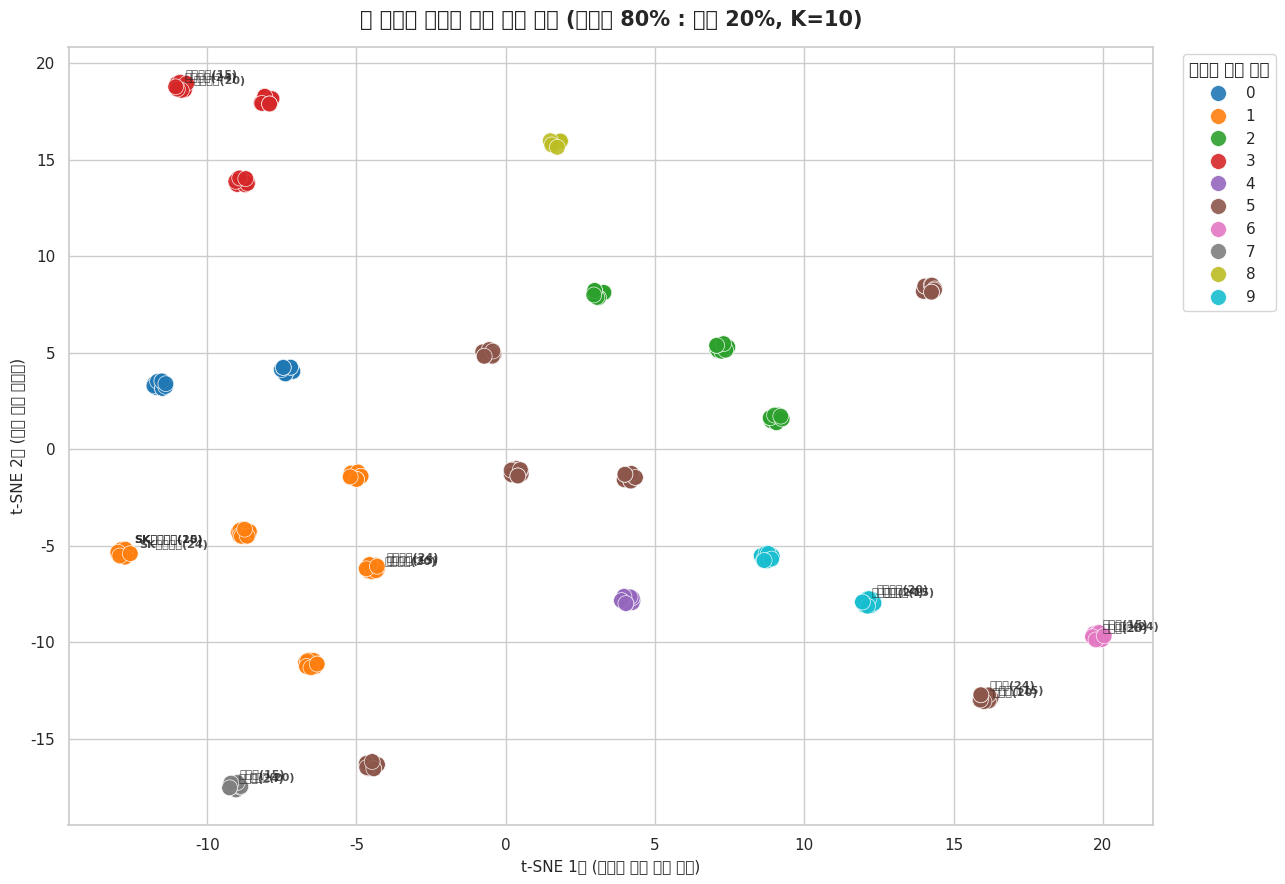

In [15]:
import sqlite3
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE

# 1. 시각화 한글 설정
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid")

# 2. DB 데이터 로드 및 텍스트/재무 분리
db_path = "real_dart_10years_hybrid.db"
conn = sqlite3.connect(db_path)
df = pd.read_sql_query("SELECT id, corp_name, year, features_json FROM high_dimensional_panel", conn)
conn.close()

X_hybrid = np.array([json.loads(row) for row in df['features_json']])
X_text = X_hybrid[:, :768]
X_finance = X_hybrid[:, 768:]

# 3. 개별 정규화(Standardization) 수행
X_text_scaled = StandardScaler().fit_transform(X_text)
X_finance_scaled = StandardScaler().fit_transform(X_finance)

# ================================================================================
# 🌟 [가중치 제어 연산] 텍스트 80% : 재무 20% 반영 및 결합
# ================================================================================
w_text = 0.8
w_finance = 0.2

# 가중치를 행렬에 물리적으로 곱해 하이브리드 공간에서의 거리를 제어합니다.
X_weighted = np.hstack([X_text_scaled * w_text, X_finance_scaled * w_finance])
print(f"📊 가중치 매핑 완료 (텍스트 비중: {w_text}, 재무 비중: {w_finance})")

# ================================================================================
# 🎯 [K-Means 최적화] 실루엣 스코어 기반 최적의 K값 자동 탐색 (2~10개 후보)
# ================================================================================
best_k = 2
best_score = -1
silhouette_samples = []

for k in range(2, 11):
    kmeans_test = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels_test = kmeans_test.fit_predict(X_weighted)
    score = silhouette_score(X_weighted, labels_test)
    silhouette_samples.append((k, score))

    if score > best_score:
        best_score = score
        best_k = k

print(f"📈 [최적화 결과] 오토 튜닝된 최적의 테마 개수(K)는 [{best_k}개] 입니다. (실루엣 점수: {best_score:.4f})")

# 최종 결정된 Best K로 K-Means 훈련
final_kmeans = KMeans(n_clusters=best_k, init='k-means++', n_init=10, random_state=42)
df['theme_cluster'] = final_kmeans.fit_predict(X_weighted)

# ================================================================================
# 📋 4. 가중 최적화 결과 터미널 보고서 출력
# ================================================================================
print("\n📋 [텍스트 80% 가중 K-Means 테마별 소속 현황]")
print("=" * 90)

grouped = df.groupby('theme_cluster')
for cluster_id, group in grouped:
    print(f"\n📁 [가중 통합 테마 #{cluster_id}] (총 {len(group)}개 시계열 맵핑)")
    corps_in_cluster = group.apply(lambda r: f"{r['corp_name']}({r['year']})", axis=1).tolist()

    # 가로로 이쁘게 정렬하여 출력
    chunk_size = 6
    for i in range(0, len(corps_in_cluster), chunk_size):
        print("  " + ", ".join(corps_in_cluster[i:i+chunk_size]))
print("=" * 90)

# ================================================================================
# 🎨 5. 2차원 공간 투영 및 결과 시각화 (t-SNE)
# ================================================================================
print("\n🔮 보고서 제출용 가중 하이브리드 클러스터 시각화 맵 생성 중...")
tsne = TSNE(n_components=2, perplexity=20, random_state=42, n_iter=1000)
X_tsne = tsne.fit_transform(X_weighted)

df['tsne_x'] = X_tsne[:, 0]
df['tsne_y'] = X_tsne[:, 1]

plt.figure(figsize=(13, 9))
sns.scatterplot(
    data=df, x='tsne_x', y='tsne_y', hue='theme_cluster',
    palette="tab10", s=130, alpha=0.9, edgecolors='w', linewidth=0.5
)

# 텍스트 라벨 중복 최소화 표시 (트렌드 확인용 주요 샘플링 가이드)
target_show = ['삼성전자', '현대차', '네이버', '셀트리온', '한국전력', '카카오', 'SK하이닉스']
for idx, row in df.iterrows():
    if row['corp_name'] in target_show and row['year'] in [2015, 2020, 2024]:
        plt.text(
            row['tsne_x'] + 0.3, row['tsne_y'] + 0.3,
            f"{row['corp_name']}({str(row['year'])[2:]})",
            fontsize=8, weight='semibold', alpha=0.8
        )

plt.title(f"📊 가중치 밸런싱 테마 매핑 결과 (텍스트 {int(w_text*100)}% : 재무 {int(w_finance*100)}%, K={best_k})", fontsize=15, weight='bold', pad=15)
plt.xlabel("t-SNE 1축 (텍스트 모달 지배 공간)", fontsize=11)
plt.ylabel("t-SNE 2축 (재무 피처 반영축)", fontsize=11)
plt.legend(title="최적화 테마 범주", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()